# Continual learning for second-life EV battery health: the complete project in one notebook

21CSC314P Big Data Essentials, Review 2. Runs on Google Colab (CPU is enough; about 25 minutes). It uses the repository's own code and its committed results, so every number shown traces to a results file written on a clean commit (`docs/RESULTS.md`, `docs/DECISIONS.md`).

| Section | What it shows | Source |
|---|---|---|
| 1. Setup | clone, pinned libraries, Java for Spark | repository |
| 2. Tests | the unit tests (synthetic data in temporary folders only) | `tests/` |
| 3. Big-data preprocessing | full-dataset preprocessing results and the Spark validation; then a **live run** of the Spark pipeline on a checksummed real subset of S6 | committed results; live demo |
| 4. Forecasting benchmarks | S1 and S6 continual stream (P1), unseen cells or conditions (P2) with reuse classes, first-life pretraining (P3) | committed results |
| 5. Proposed model vs existing models | residual TFT + EWC against the neural variants and the conventional baselines: RMSE, paired tests with the replication verdict, forgetting, per-group errors, figures | committed results (D23) |
| 6. RC-TFT and literature baselines (D24) | shown when their results are committed | committed results, if present |
| 7. Shrinkage, unseen conditions and intervals (D25–D27) | shrunk residual TFT, unseen-condition errors, conformal intervals and their coverage per condition | committed results (D25–D27) |
| 8. Conclusions | what the results support, and the limitations | — |

**Definitions.** SOH = capacity / first valid measured capacity × 100 (relative SOH, not nominal capacity). The task is to forecast SOH 1–3 (E1) or 1–6 (E2) capacity checks ahead. Errors are RMSE in percentage points (pp) of SOH. Continual-learning runs: 10 task orders × 5 seeds per seed set (main: seeds 0–4, replicate: seeds 5–9). A difference counts as a finding only if it replicates (D21 rule: Holm-corrected p < 0.05 in both seed sets, same sign, |difference| ≥ 0.05 pp in both).

## 1. Setup

**Running locally** (VS Code or Jupyter): select the repository's `.venv` as the kernel (Python 3.11, `pip install -r requirements.txt`). The setup cells then use the local checkout and that environment, install nothing, and skip the live download demo of section 3.2 (it would overwrite the full local `data/wheeler_checks.csv` and `data/s6_ageing_blocks.csv`). The steps below are for Colab only.

The repository is private, so cloning needs a GitHub token with read access to it:

1. On GitHub: Settings → Developer settings → Personal access tokens → Fine-grained tokens → Generate new token. Repository access: only this repository; permissions: Contents = Read-only. Copy the token.
2. In Colab: the key icon (Secrets) in the left sidebar → Add new secret, name `GITHUB_TOKEN`, value = the token, and switch on notebook access.

Without the secret, the next cell asks for the token in a hidden prompt instead. The token is used for the clone only and is removed from the clone's configuration afterwards; it never appears in the notebook's output.

The project's libraries are installed into a separate environment (`/content/venv`), so the session never needs a restart: one **Runtime → Run all** runs the whole notebook (about 25 minutes).

In [1]:
BRANCH = "main"
REPO = "TarunSitaraman/continual-learning-heterogeneous-second-life-ev-batteries"

import os, subprocess, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from getpass import getpass
    if not os.path.isdir("/content/repo"):
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:   # secret missing or notebook access not granted
            token = getpass("GitHub token with read access to the repository (input hidden): ")
        clone = subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, f"https://{token}@github.com/{REPO}.git",
                                "/content/repo"], capture_output=True, text=True)
        del token
        if clone.returncode != 0:
            raise SystemExit("Clone failed: check that the token has read access to " + REPO)
        # Remove the token from the clone's saved remote.
        subprocess.run(["git", "-C", "/content/repo", "remote", "set-url", "origin", f"https://github.com/{REPO}.git"], check=True)
    REPO_ROOT = Path("/content/repo")
else:   # local run: the checkout this notebook lives in
    REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts" / "make_d24_outputs.py").is_file())
os.chdir(REPO_ROOT)
print("Colab" if IN_COLAB else "local", "|", REPO_ROOT, "|",
      subprocess.run(["git", "log", "-1", "--format=%h %ad %s", "--date=short"], capture_output=True, text=True).stdout)

local | c:\Users\Tarun\Downloads\ML handover | 4073bd9 2026-10-23 docs: state the learning-rate grid and that the grid-edge rule applies to every tuned grid



In [2]:
%%capture install_log
# On Colab, the project's pinned libraries (requirements.txt) go into a separate environment, /content/venv, which
# inherits Colab's own packages (torch). Tests, Spark and every script run there; this notebook's Python keeps Colab's
# libraries and only reads files and draws tables and figures, so no session restart is needed.
# Locally, the scripts run in the repository's .venv and nothing is installed.
import os, shutil, subprocess, sys
os.chdir(REPO_ROOT)
if IN_COLAB:
    VENV = "/content/venv"
    PY = VENV + "/bin/python"
    if not os.path.exists(PY):
        !{sys.executable} -m pip install -q uv
        !{sys.executable} -m uv venv -q --system-site-packages --python {sys.executable} {VENV}
        !grep -v -E "^(jupyter|torch)==" /content/repo/requirements.txt > /tmp/requirements_colab.txt
        !{sys.executable} -m uv pip install -q --python {PY} -r /tmp/requirements_colab.txt
    if subprocess.run([PY, "-c", "import torch"], capture_output=True).returncode != 0:      # no inherited torch
        !{sys.executable} -m uv pip install -q --python {PY} torch --index-url https://download.pytorch.org/whl/cpu
    if not shutil.which("java"):
        !apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless

In [3]:
import glob, os, shutil, subprocess, sys
os.chdir(REPO_ROOT)   # also after a session restart
if IN_COLAB:
    java = (sorted(glob.glob("/usr/lib/jvm/java-17-openjdk-*")) or sorted(glob.glob("/usr/lib/jvm/*")))[0]
    os.environ["JAVA_HOME"] = java
    os.environ["PATH"] = java + "/bin:" + os.environ["PATH"]
    PY = "/content/venv/bin/python"   # project environment (pinned libraries)
else:
    venv = [REPO_ROOT / ".venv" / "Scripts" / "python.exe", REPO_ROOT / ".venv" / "bin" / "python"]
    PY = str(next((p for p in venv if p.exists()), sys.executable))   # the repository's .venv (pinned libraries)
os.environ["MPLBACKEND"] = "Agg"   # scripts and tests write figures to files; this notebook still shows them inline


def run(*args, tail=None):
    """Run a project script with the project's Python; print its output (the last ``tail`` lines if given)."""
    p = subprocess.run([PY, *map(str, args)], capture_output=True, text=True, encoding="utf-8", errors="replace")
    lines = (p.stdout + p.stderr).rstrip().splitlines()
    print("\n".join(lines[-tail:] if tail else lines))
    return p.returncode


check = subprocess.run([PY, "-c", "import sys, numpy, pandas, sklearn, torch, pyspark; print('project environment: Python', "
                        "sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__, '| scikit-learn', "
                        "sklearn.__version__, '| torch', torch.__version__, '| PySpark', pyspark.__version__)"],
                       capture_output=True, text=True)
print(check.stdout or check.stderr)
assert check.returncode == 0, "the project environment is incomplete: see install_log.show() in the previous cell"
java_version = subprocess.run(["java", "-version"], capture_output=True, text=True) if shutil.which("java") else None
print(java_version.stderr.splitlines()[0] if java_version else "java: not found (needed only for the Spark demo)")
import importlib.util, json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
spec = importlib.util.spec_from_file_location("d24_outputs", REPO_ROOT / "scripts" / "make_d24_outputs.py")
O = importlib.util.module_from_spec(spec)
spec.loader.exec_module(O)   # table and verdict code shared with the paper tables; its main() is not called
%matplotlib inline

def show(fig_name, width=760):
    p = REPO_ROOT / "paper" / "figures" / fig_name
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print("missing figure:", fig_name)

project environment: Python 3.11.15 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | PySpark 4.2.0

java version "21.0.9" 2025-10-21 LTS


## 2. Tests

In [4]:
run("-m", "pytest", "-q", "-p", "no:cacheprovider", tail=3)


-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
189 passed, 13 warnings in 891.92s (0:14:51)


0

## 3. Big-data preprocessing

### 3.1 Results on the full data (committed)

The S6 between-check ageing data: 827 files, about 132 GB raw, 901,974,259 rows (counted). Apache Spark (PySpark, local mode on one machine) maps each file to per-cycle responses, caches the per-cycle table and reduces it with Spark SQL to 21 inputs per (cell, 100-cycle block). The Spark output is checked against an independent pandas implementation on every block.

,dataset,stage,value,unit
0,S1,"raw diagnostic files (RPT, EIS), verified",351,files
1,S1,raw size,2.2 GB,NaN
2,S1,RPTs with C/20 label and diagnostics,111,"(battery, RPT)"
3,S1,diagnostic features per RPT,47,features
4,S1,forecasting samples (h = 1-3),279,samples
5,S6 checks,"check files read from the archive, verified",1007,files
6,S6 checks,uncompressed size of the files read,20.0 GB,NaN
7,S6 checks,capacity checks parsed,847,checks
8,S6 checks,valid (labelled) checks,843,checks
9,S6 checks,forecasting samples (h = 1-3),2409,samples


{'engine': 'Apache Spark 4.2.0 (PySpark), local[6] on one machine', 'blocks': 827, 'cycles': 82529, 'seconds': 1175.2, 'compared_blocks': 827, 'criterion': '|spark - pandas| <= 1e-09 * |pandas| + 1e-12, same missing values', 'matches_pandas': True}
largest |Spark - pandas| over all inputs: 1.9895196601282805e-13
causality check: 827 blocks, 0 violations at valid checks


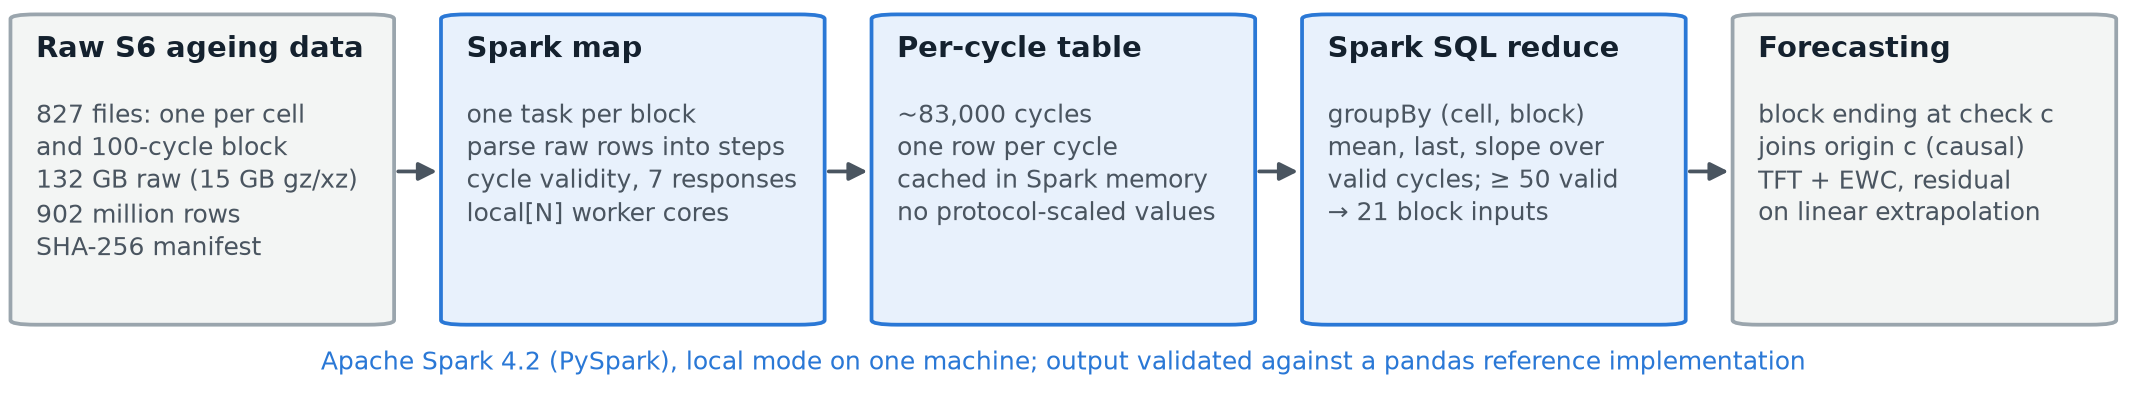

In [5]:
if IN_COLAB:   # locally the committed table is shown as it is (a rebuild would rewrite committed results files)
    subprocess.run([PY, "scripts/make_preprocessing_table.py"], capture_output=True, check=True)
display(pd.read_csv("results/tables/preprocessing.csv")[["dataset", "stage", "value", "unit"]])
v = json.loads(Path("results/d22_spark_validation.json").read_text())
print({k: v[k] for k in ("engine", "blocks", "cycles", "seconds", "compared_blocks", "criterion", "matches_pandas")})
print("largest |Spark - pandas| over all inputs:", max(d["max_abs"] for d in v["per_input"].values()))
a = json.loads(Path("results/d22_ageing_report.json").read_text())
print("causality check:", a["causality"]["blocks_checked"], "blocks,", a["causality"]["violations_at_valid_checks"],
      "violations at valid checks")
show("spark_pipeline.png", 900)

### 3.2 Live run on a real subset of S6

Downloads (checked against the checksums committed in `docs/external_data/metadata/`): the authors' `extractedData.mat` (MD5), the capacity-check files of cell 1a (CRC-32, read from its zip with HTTP range requests) and one eighth of cell 1a's ageing files (about 4 files of roughly 1.6 million rows each). Labels are rebuilt and checked against the authors' capacities; the ageing inputs are extracted with pandas and with Spark, and compared. Numbers in this subsection come from the subset: a demonstration of the pipeline, not reportable results. Manifests of this partial download go to `/content`, so the committed manifests stay unchanged.

In [6]:
# Colab only: locally it would overwrite the full data/wheeler_checks.csv and data/s6_ageing_blocks.csv.
RUN_REAL_DATA_DEMO = IN_COLAB and os.environ.get("RUN_REAL_DATA_DEMO", "1") == "1"   # set to False to skip the downloads
CELL = "Cell1a"

import hashlib, json, urllib.request
from pathlib import Path
raw = Path("data/raw/wheeler2025"); raw.mkdir(parents=True, exist_ok=True)
record = json.loads(Path("docs/external_data/metadata/wheeler2025_lfp_dataverse.dataset.json").read_text())
files = record["data"]["latestVersion"]["files"] if "data" in record else record["latestVersion"]["files"]
mat = next(f["dataFile"] for f in files if f["dataFile"]["filename"] == "extractedData.mat")
target = raw / "extractedData.mat"
if RUN_REAL_DATA_DEMO and not target.exists():
    urllib.request.urlretrieve(f"https://entrepot.recherche.data.gouv.fr/api/access/datafile/{mat['id']}", target)
if RUN_REAL_DATA_DEMO:
    md5 = hashlib.md5(target.read_bytes()).hexdigest()
    assert md5 == mat["md5"], f"MD5 mismatch: {md5} != {mat['md5']}"
    print("extractedData.mat MD5 verified:", md5)
else:
    print("live demo switched off" + ("" if IN_COLAB else " (local run)") + ": section 3.2 is skipped")

live demo switched off (local run): section 3.2 is skipped


In [7]:
if RUN_REAL_DATA_DEMO:
    !{PY} scripts/fetch_wheeler_characterisation.py --cells {CELL} --manifest /content/charac_manifest.json
    !{PY} scripts/build_wheeler_features.py --workers 2

In [8]:
if RUN_REAL_DATA_DEMO:
    checks = pd.read_csv("data/wheeler_checks.csv")
    print(f"{len(checks)} checks of {checks['cell'].nunique()} cell(s); {int(checks['valid'].sum())} with a C/25 label")
    display(checks[["cell", "Battery_ID", "cycle", "check_time", "Capacity_Ah", "SOH_Percent", "valid"]].head(10))

In [9]:
if RUN_REAL_DATA_DEMO:
    !{PY} scripts/fetch_wheeler_characterisation.py --cells {CELL} --kind aging --shard 0/8 --manifest /content/aging_manifest.json

**Pandas reference** (`scripts/build_s6_ageing_features.py`): per-cycle responses (end-of-charge and end-of-discharge voltage, CV hold time and final current, relaxation after charge and discharge) and block aggregates (mean, last value, least-squares slope).

In [10]:
if RUN_REAL_DATA_DEMO:
    !{PY} scripts/build_s6_ageing_features.py --workers 2

**Apache Spark** (`scripts/spark_ageing_features.py`): one map task per ageing file parses it into per-cycle responses; the per-cycle table is cached; Spark SQL groups by (cell, block) into the same aggregates; the output is compared with the pandas reference: |Spark − pandas| ≤ 1e-9·|pandas| + 1e-12 and the same missing values.

In [11]:
if RUN_REAL_DATA_DEMO:
    !{PY} scripts/spark_ageing_features.py --cores 2 --tag colab
    v = json.loads(Path("results/d22_spark_validation_colab.json").read_text())
    print({k: v[k] for k in ("engine", "blocks", "cycles", "seconds", "compared_blocks", "matches_pandas")})
    print("largest |Spark - pandas|:", max(d["max_abs"] for d in v["per_input"].values()))

In [12]:
if RUN_REAL_DATA_DEMO:
    blocks = pd.read_csv("data/s6_ageing_blocks_spark_colab.csv")
    display(blocks.iloc[:, :8])

The demo rewrote `results/d22_ageing_report.json` and other files for its subset; every committed results file is restored from Git before the results sections.

In [13]:
if RUN_REAL_DATA_DEMO:   # only the demo changes results files
    subprocess.run(["git", "checkout", "--", "results", "paper"], check=True)
print(subprocess.run(["git", "status", "--short", "results", "paper"], capture_output=True, text=True).stdout[:400]
      or "results match the committed files")

results match the committed files


## 4. Forecasting benchmarks (committed results)

### 4.1 Continual stream (P1): S1 (six second-life NMC cells) and S6 (seven LFP usage conditions)
Final average test RMSE over the stream (pp), skill = 1 − RMSE / RMSE of persistence, forgetting in pp. Inputs of D18 (S1) and D20 (S6).

S1


,name,rmse_pp_mean,rmse_pp_sd,n_runs,skill_vs_persistence,forgetting_pp_mean
2,"Ridge, usage only",0.450,NaN,1.0,0.288,NaN
13,TFT joint (upper bound),0.455,0.017,5.0,0.280,NaN
11,TFT + EWC,0.462,0.019,50.0,0.268,0.016
5,"Gradient boosting, F1",0.466,NaN,1.0,0.264,NaN
10,TFT fine-tuning,0.467,0.014,50.0,0.261,0.026
12,"TFT + EWC, F0",0.472,0.020,50.0,0.254,0.019
7,MLP replay,0.475,0.021,50.0,0.249,0.025
4,"Ridge, F1",0.491,NaN,1.0,0.223,NaN
6,MLP fine-tuning,0.492,0.029,50.0,0.222,0.030
8,MLP + EWC,0.497,0.033,50.0,0.213,0.040


S6


,name,rmse_pp_mean,rmse_pp_sd,n_runs,skill_vs_persistence,forgetting_pp_mean
15,Linear extrapolation,0.343,NaN,1.0,0.792,NaN
19,"Gradient boosting, F1",0.372,NaN,1.0,0.773,NaN
23,MLP joint (upper bound),0.414,0.037,5.0,0.748,NaN
27,TFT joint (upper bound),0.427,0.049,5.0,0.741,NaN
20,MLP fine-tuning,0.531,0.151,50.0,0.677,0.207
22,MLP + EWC,0.540,0.176,50.0,0.671,0.212
21,MLP replay,0.597,0.178,50.0,0.637,0.212
18,"Ridge, F1",0.605,NaN,1.0,0.632,NaN
26,"TFT + EWC, F0",0.621,0.257,50.0,0.623,0.176
25,TFT + EWC,0.677,0.261,50.0,0.588,0.274


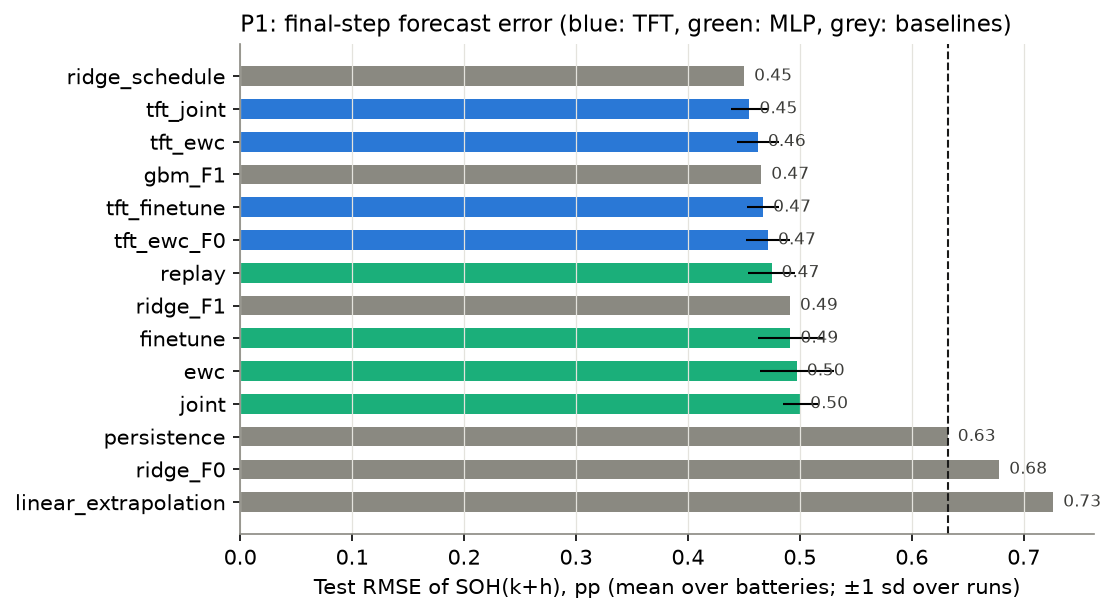

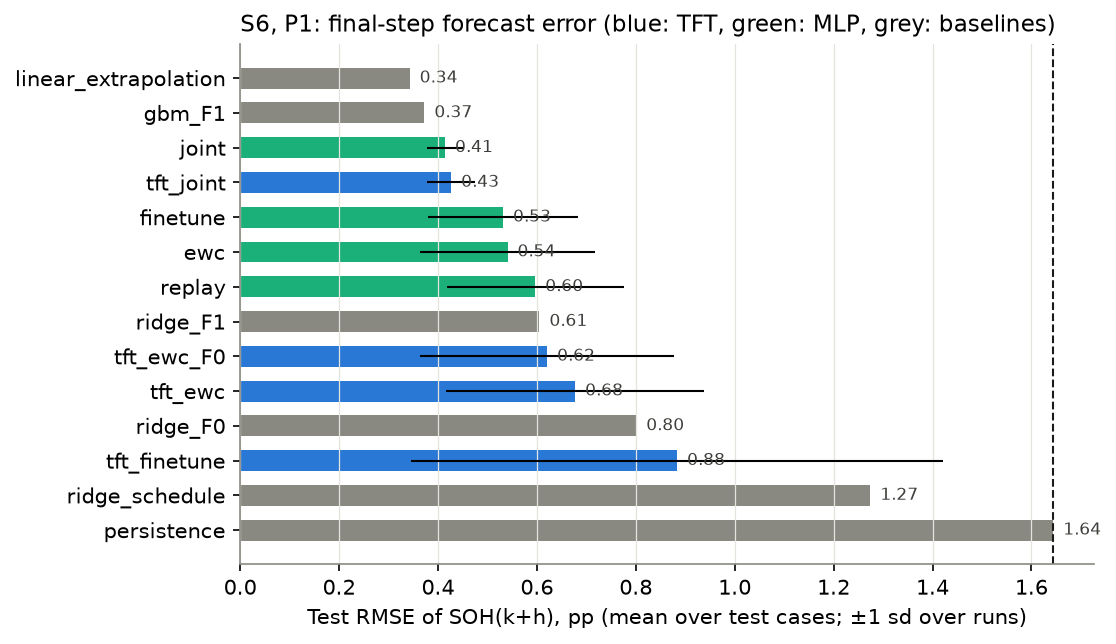

In [14]:
p1 = pd.read_csv("results/tables/p1.csv")
for ds in ("S1", "S6"):
    print(ds)
    display(p1[p1["dataset"] == ds][["name", "rmse_pp_mean", "rmse_pp_sd", "n_runs", "skill_vs_persistence",
                                      "forgetting_pp_mean"]].sort_values("rmse_pp_mean").round(3))
show("12_p1_rmse.png", 640); show("13_p1_rmse.png", 640)

### 4.2 Unseen cell or usage condition (P2) and reuse classes
Leave one group out; S6 reuse classes C0–C3 from the forecast SOH (accuracy and macro-F1 against the measured class).

In [15]:
p2 = pd.read_csv("results/tables/p2.csv")
display(p2.sort_values(["dataset", "rmse_pp_mean"]).round(3))

,dataset,method,name,rmse_pp_mean,rmse_pp_min,rmse_pp_max,hardest_group,class_accuracy,class_macro_f1
5,S1,gbm_F1,"Gradient boosting, F1",0.219,0.091,0.299,w8,NaN,NaN
6,S1,mlp,MLP,0.285,0.149,0.389,w8,NaN,NaN
7,S1,tft,TFT,0.292,0.199,0.377,v5,NaN,NaN
2,S1,ridge_schedule,"Ridge, usage only",0.301,0.172,0.409,w8,NaN,NaN
4,S1,ridge_F1,"Ridge, F1",0.320,0.161,0.477,v5,NaN,NaN
3,S1,ridge_F0,"Ridge, F0",0.418,0.158,0.779,v5,NaN,NaN
1,S1,linear_extrapolation,Linear extrapolation,0.511,0.284,0.725,v5,NaN,NaN
0,S1,persistence,Persistence,0.545,0.436,0.688,v5,NaN,NaN
13,S6,gbm_F1,"Gradient boosting, F1",0.710,0.395,1.839,case7,0.966,0.882
14,S6,mlp,MLP,0.821,0.476,2.225,case7,0.962,0.868


### 4.3 First-life pretraining (P3) and the input ablation
Pretraining on 369 first-life cells (S7–S9, 36,711 samples) before the S6 stream; final average test RMSE on S6, main / replicate seeds.

set,main,replicate
method,,
tft_scratch_finetune,0.401,0.415
mlp_scratch_finetune,0.496,0.475
tft_pre_ewc,0.509,0.591
tft_pre_finetune,0.525,0.606
mlp_pre_ewc,0.735,0.631
mlp_pre_finetune,0.844,0.777


baselines: {'persistence': 1.644, 'linear_extrapolation': 0.343, 'ridge_schedule': 1.079, 'ridge_shared': 1.184, 'gbm_shared': 0.451}


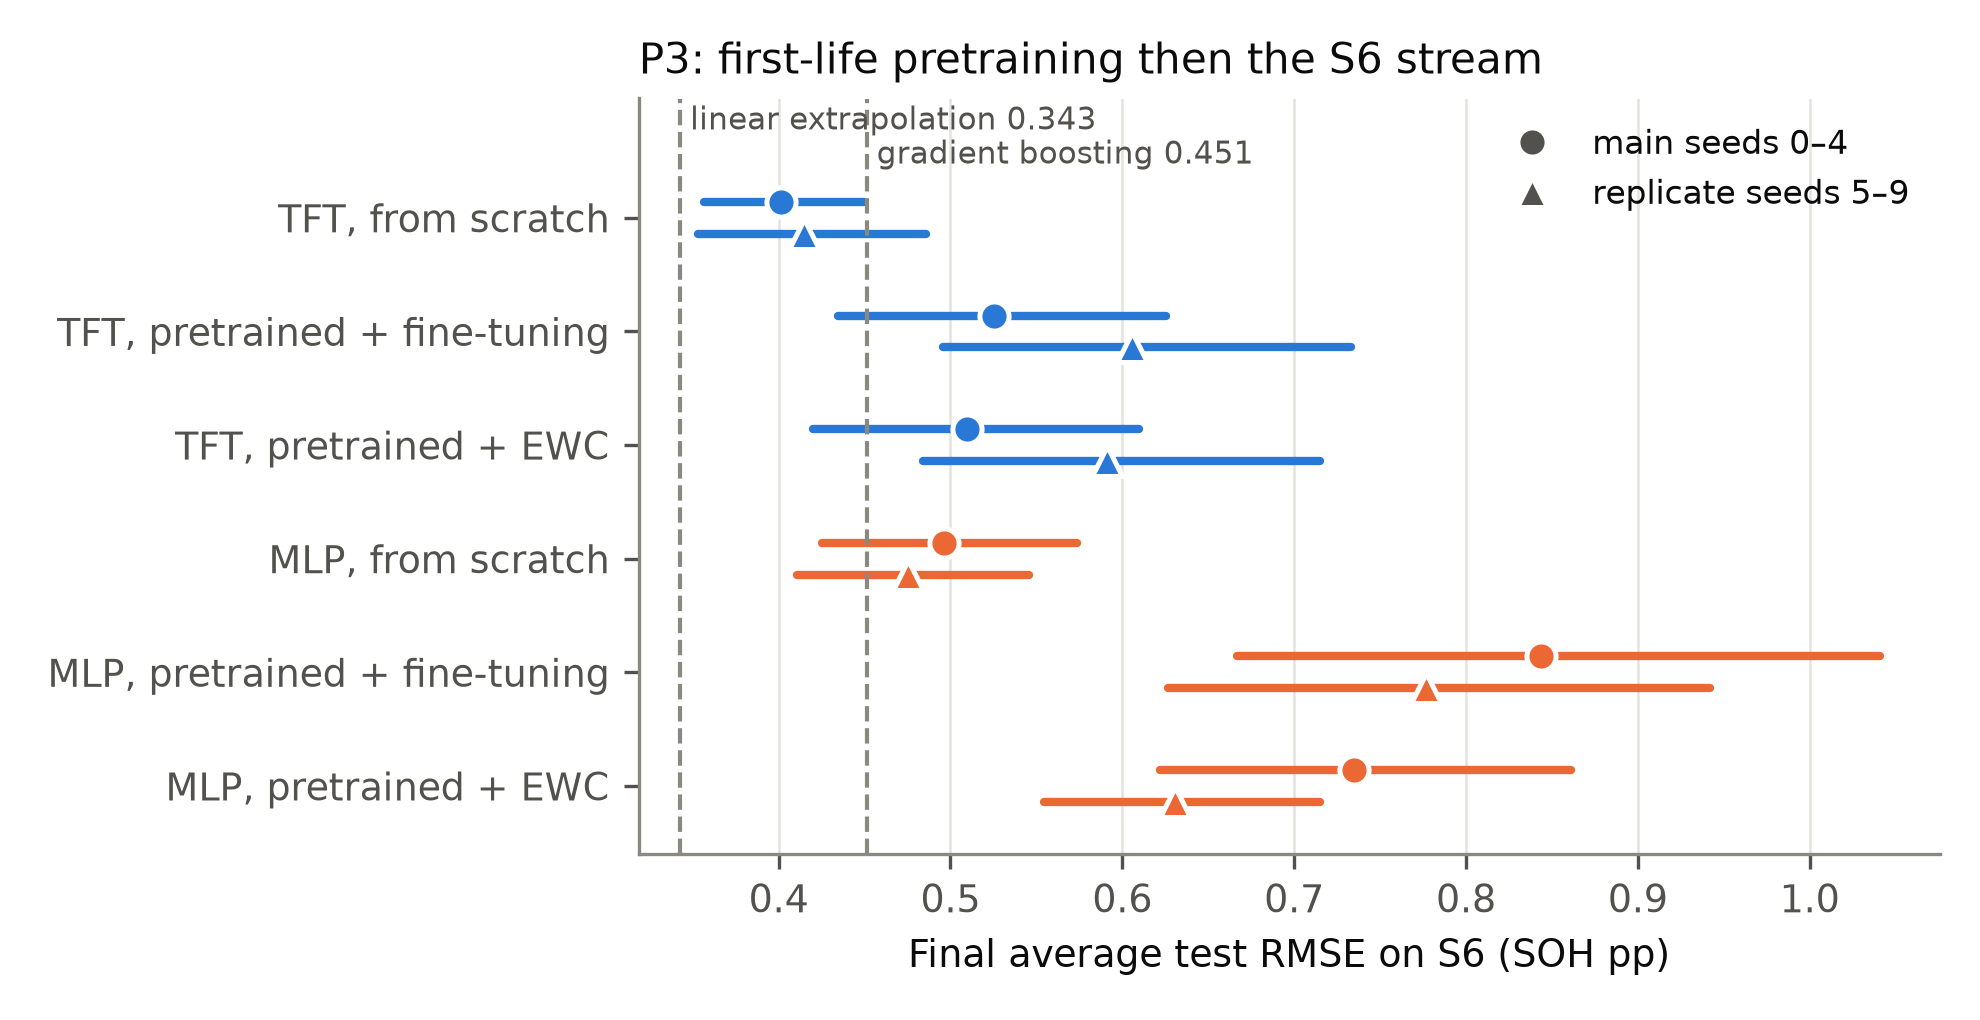

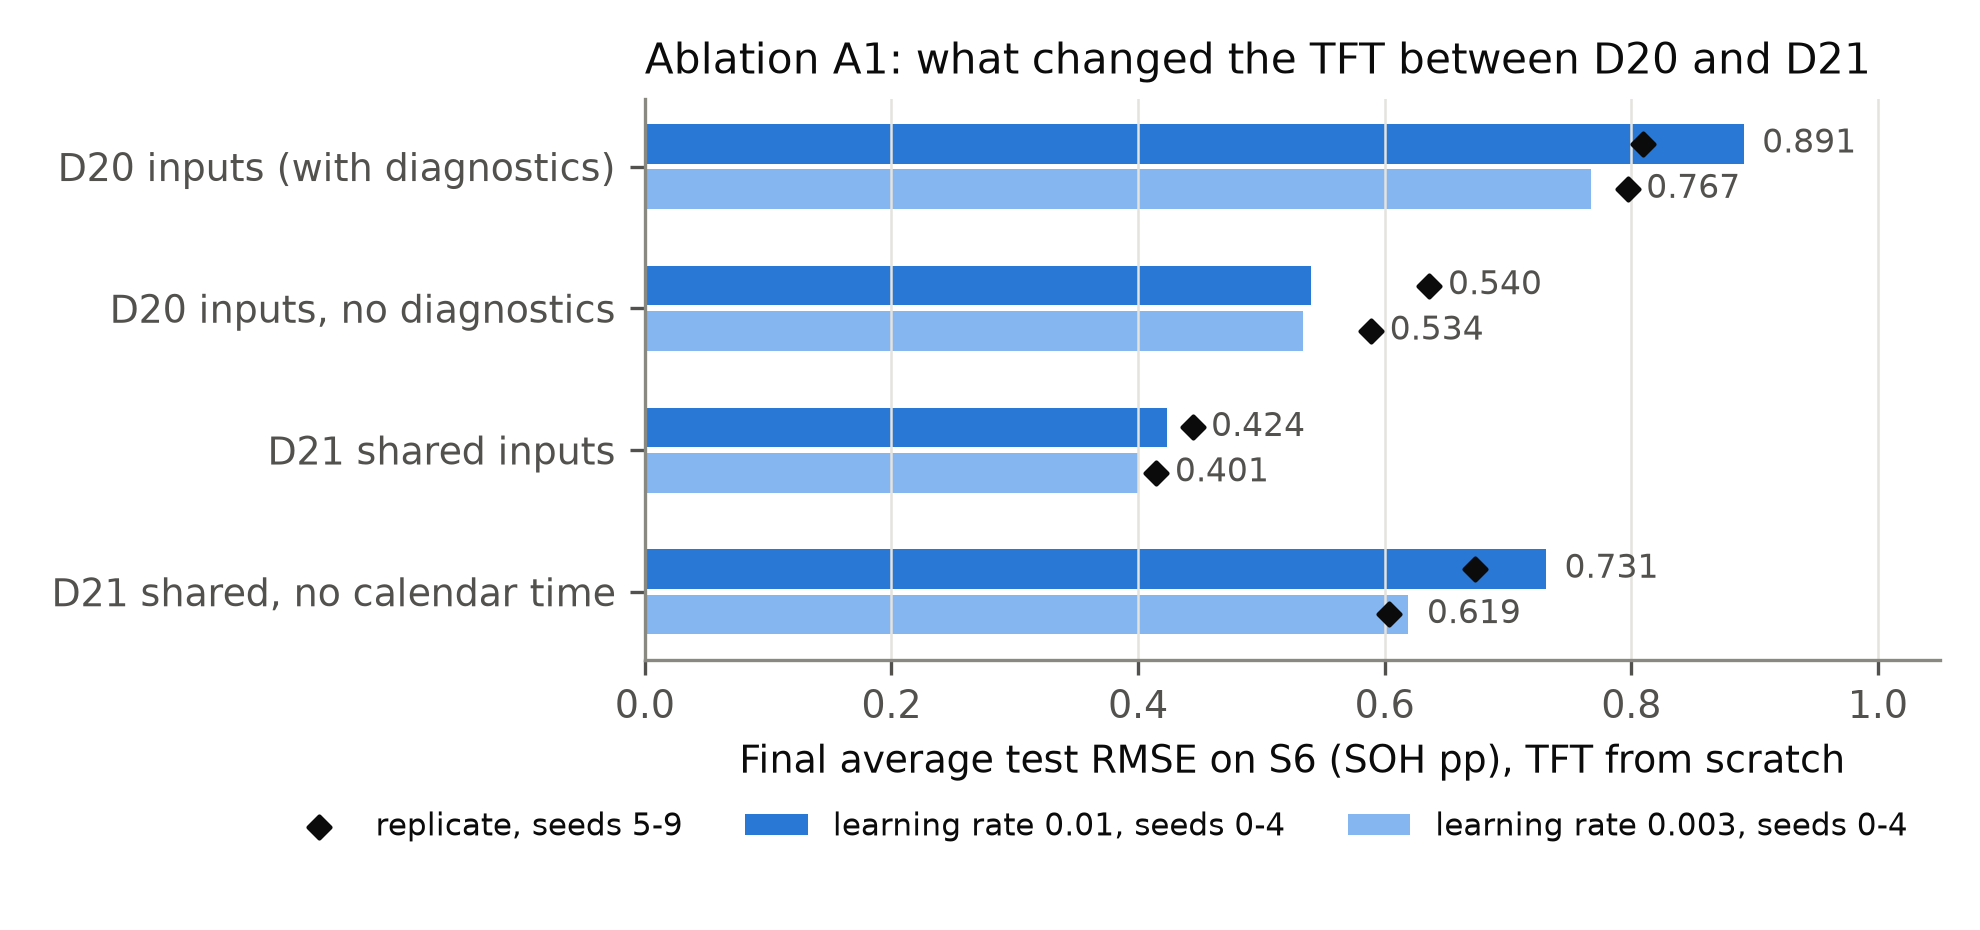

In [16]:
p3 = json.loads(Path("results/forecasting_d21_p3.json").read_text())
s = pd.DataFrame(p3["summary"]).pivot(index="method", columns="set", values="final_avg_error_mean").round(3)
display(s.sort_values("main"))
print("baselines:", {b["method"]: round(b["rmse_final_mean_over_tasks"], 3) for b in p3["baselines"]})
show("d21_p3_final_error.png", 640); show("d21_ablation_a1.png", 640)

## 5. Proposed model against existing models (D23, committed results)

Residual TFT + EWC (forecast = linear extrapolation + a correction learned by a Temporal Fusion Transformer with Elastic Weight Consolidation) against the direct TFT, the MLP variants and the conventional models (linear extrapolation, gradient boosting, ridge, persistence), on the S6 stream: E1 = horizons 1–3, E2 = horizons 1–6. Tests: paired two-sided Wilcoxon against the reference, Holm-corrected within each seed set; `diff` = reference − other (negative favours residual TFT + EWC).

In [17]:
REF = "tft_residual_ewc"
data = {}
for exp in ("e1", "e2"):
    path = REPO_ROOT / "results" / f"forecasting_d23_{exp}.json"
    data[exp] = json.loads(path.read_text())
    env = data[exp]["environment"]
    print(f"{exp}: {path.name}, decision {data[exp]['decision']}, profile {data[exp]['profile']}, "
          f"horizons {data[exp]['horizons']}, {data[exp]['n_samples']} samples, commit {env['git_commit'][:7]}, "
          f"git_dirty={env['git_dirty']}")

e1: forecasting_d23_e1.json, decision D23, profile paper, horizons [1, 2, 3], 2409 samples, commit 5ae2f84, git_dirty=False
e2: forecasting_d23_e2.json, decision D23, profile paper, horizons [1, 2, 3, 4, 5, 6], 4638 samples, commit 5ae2f84, git_dirty=False


### 5.1 Final test RMSE of every method

In [18]:
def comparison_view(exp):
    c = O.comparison(data[exp])
    view = c[["label", "kind", "rmse_main_mean", "rmse_main_sd", "rmse_replicate_mean", "rmse_replicate_sd",
              "forgetting_main"]].rename(columns={
        "label": "method", "rmse_main_mean": "RMSE main (pp)", "rmse_main_sd": "s.d. main",
        "rmse_replicate_mean": "RMSE replicate (pp)", "rmse_replicate_sd": "s.d. replicate",
        "forgetting_main": "forgetting main (pp)"})
    return c, view

comp = {}
for exp in ("e1", "e2"):
    comp[exp], view = comparison_view(exp)
    print(f"{exp.upper()} (horizons {data[exp]['horizons']}), sorted by main RMSE")
    display(view.round(3))

E1 (horizons [1, 2, 3]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp)
0,"TFT + EWC, residual",continual (stream),0.339,0.164,0.314,0.067,0.100
1,Linear extrapolation,deterministic,0.343,NaN,0.343,NaN,NaN
2,"TFT fine-tuning, residual",continual (stream),0.347,0.121,0.337,0.110,0.103
3,"MLP + EWC, residual",continual (stream),0.374,0.056,0.366,0.071,0.053
4,"MLP fine-tuning, residual",continual (stream),0.405,0.082,0.403,0.084,0.082
5,"MLP fine-tuning, direct",continual (stream),0.413,0.133,0.351,0.106,0.207
6,"TFT fine-tuning, direct",continual (stream),0.424,0.191,0.444,0.207,0.151
7,Gradient boosting,fitted once on all tasks,0.451,NaN,0.451,NaN,NaN
8,"TFT + EWC, direct",continual (stream),0.504,0.206,0.487,0.213,0.228
9,"MLP + EWC, direct",continual (stream),0.519,0.286,0.527,0.239,0.216


E2 (horizons [1, 2, 3, 4, 5, 6]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp)
0,Linear extrapolation,deterministic,0.485,NaN,0.485,NaN,NaN
1,"TFT + EWC, residual",continual (stream),0.561,0.152,0.534,0.124,0.093
2,"MLP fine-tuning, residual",continual (stream),0.656,0.202,0.695,0.213,0.201
3,"TFT fine-tuning, direct",continual (stream),0.658,0.400,0.694,0.418,0.307
4,"MLP + EWC, residual",continual (stream),0.659,0.208,0.694,0.217,0.205
5,"TFT fine-tuning, residual",continual (stream),0.673,0.270,0.612,0.229,0.282
6,"MLP fine-tuning, direct",continual (stream),0.781,0.307,0.775,0.268,0.414
7,"TFT + EWC, direct",continual (stream),0.802,0.281,0.835,0.309,0.135
8,Gradient boosting,fitted once on all tasks,0.898,NaN,0.898,NaN,NaN
9,"MLP + EWC, direct",continual (stream),1.004,0.447,0.996,0.583,0.385


### 5.2 Paired tests against residual TFT + EWC, with the replication verdict

In [19]:
tests = {}
for exp in ("e1", "e2"):
    t = O.tests_table(data[exp])
    tests[exp] = t
    print(f"{exp.upper()}: reference = {t['reference'].iloc[0]}")
    display(t[["metric", "other", "diff_main", "p_holm_main", "diff_replicate", "p_holm_replicate", "verdict"]]
            .round({"diff_main": 3, "diff_replicate": 3}).style.format({"p_holm_main": "{:.2g}", "p_holm_replicate": "{:.2g}"}))

E1: reference = TFT + EWC, residual


,metric,other,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"MLP + EWC, direct",-0.180000,0.0069,-0.213000,5.8e-07,"replicated, reference better"
1,forgetting,"MLP + EWC, direct",-0.116000,0.054,-0.132000,0.0032,not replicated
2,backward_transfer,"MLP + EWC, direct",-0.129000,0.027,-0.125000,0.0087,"replicated, reference better"
3,final_avg_error,"MLP fine-tuning, direct",-0.074000,0.014,-0.037000,0.87,not replicated
4,forgetting,"MLP fine-tuning, direct",-0.107000,0.00051,-0.078000,0.0032,"replicated, reference better"
5,backward_transfer,"MLP fine-tuning, direct",-0.117000,0.00024,-0.063000,0.097,not replicated
6,final_avg_error,"MLP + EWC, residual",-0.035000,0.002,-0.052000,0.00034,not replicated
7,forgetting,"MLP + EWC, residual",0.046000,0.22,0.021000,0.87,practically equivalent
8,backward_transfer,"MLP + EWC, residual",0.004000,1,-0.007000,1,practically equivalent
9,final_avg_error,"MLP fine-tuning, residual",-0.066000,0.00097,-0.089000,6.2e-07,"replicated, reference better"


E2: reference = TFT + EWC, residual


,metric,other,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"MLP + EWC, direct",-0.443000,1.4e-11,-0.462000,1.3e-06,"replicated, reference better"
1,forgetting,"MLP + EWC, direct",-0.292000,4.9e-08,-0.327000,1.9e-05,"replicated, reference better"
2,backward_transfer,"MLP + EWC, direct",-0.266000,0.00013,-0.282000,0.0022,"replicated, reference better"
3,final_avg_error,"MLP fine-tuning, direct",-0.220000,6.5e-05,-0.241000,1.4e-06,"replicated, reference better"
4,forgetting,"MLP fine-tuning, direct",-0.321000,8.1e-08,-0.315000,4.3e-07,"replicated, reference better"
5,backward_transfer,"MLP fine-tuning, direct",-0.272000,9.3e-06,-0.269000,9.6e-07,"replicated, reference better"
6,final_avg_error,"MLP + EWC, residual",-0.098000,0.096,-0.160000,9.4e-07,not replicated
7,forgetting,"MLP + EWC, residual",-0.112000,0.013,-0.139000,0.00023,"replicated, reference better"
8,backward_transfer,"MLP + EWC, residual",-0.122000,0.0042,-0.134000,0.0004,"replicated, reference better"
9,final_avg_error,"MLP fine-tuning, residual",-0.095000,0.096,-0.162000,7.2e-07,not replicated


#### Summary: residual TFT + EWC against the conventional (non-neural) models

In [20]:
conventional = [O.label(m) for m in ("linear_extrapolation", "gbm_shared", "ridge_schedule", "ridge_shared", "persistence")]
rows = []
for exp in ("e1", "e2"):
    t = tests[exp]
    t = t[(t["metric"] == "final_avg_error") & t["other"].isin(conventional)]
    rows += [{"experiment": exp.upper(), "baseline": r.other, "diff main (pp)": r.diff_main,
              "diff replicate (pp)": r.diff_replicate, "verdict": r.verdict} for r in t.itertuples()]
display(pd.DataFrame(rows).round(3))

,experiment,baseline,diff main (pp),diff replicate (pp),verdict
0,E1,Persistence,-1.305,-1.331,"replicated, reference better"
1,E1,Linear extrapolation,-0.004,-0.029,practically equivalent
2,E1,"Ridge, usage only",-0.740,-0.765,"replicated, reference better"
3,E1,Ridge,-0.845,-0.870,"replicated, reference better"
4,E1,Gradient boosting,-0.112,-0.138,"replicated, reference better"
5,E2,Persistence,-2.106,-2.133,"replicated, reference better"
6,E2,Linear extrapolation,0.076,0.049,not replicated
7,E2,"Ridge, usage only",-1.092,-1.119,"replicated, reference better"
8,E2,Ridge,-1.640,-1.668,"replicated, reference better"
9,E2,Gradient boosting,-0.337,-0.365,"replicated, reference better"


### 5.3 Figure: final test RMSE (main seed set, mean ± s.d. over 50 runs)

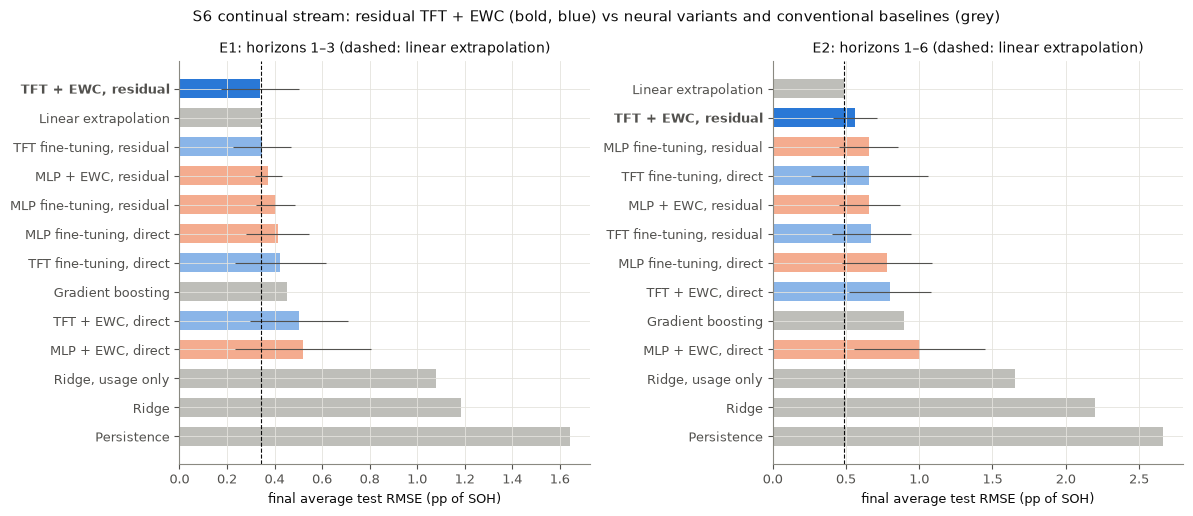

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=False)
for ax, exp in zip(axes, ("e1", "e2")):
    c = comp[exp].sort_values("rmse_main_mean", ascending=False)
    colours = ["#2a78d6" if m == REF else O.FAMILY_COLOUR.get(O.family(m), O.GREY) if O.family(m) else O.GREY
               for m in c["method"]]
    alpha = [1.0 if m == REF else 0.55 for m in c["method"]]
    bars = ax.barh(c["label"], c["rmse_main_mean"], xerr=c["rmse_main_sd"].fillna(0), color=colours,
                   height=0.65, error_kw={"elinewidth": 0.8, "ecolor": O.INK2})
    for b, a in zip(bars, alpha):
        b.set_alpha(a)
    lin = c.loc[c["method"] == "linear_extrapolation", "rmse_main_mean"].iloc[0]
    ax.axvline(lin, color=O.INK, linestyle="--", linewidth=0.8)
    ax.set_xlabel("final average test RMSE (pp of SOH)")
    ax.set_title(f"{exp.upper()}: horizons {data[exp]['horizons'][0]}–{data[exp]['horizons'][-1]} "
                 f"(dashed: linear extrapolation)")
    for lbl in ax.get_yticklabels():
        if lbl.get_text() == O.label(REF):
            lbl.set_fontweight("bold")
fig.suptitle("S6 continual stream: residual TFT + EWC (bold, blue) vs neural variants and conventional baselines (grey)")
fig.tight_layout()
plt.show()

### 5.4 Forgetting: what EWC adds to the residual TFT

In [22]:
rows = []
for exp in ("e1", "e2"):
    runs = pd.DataFrame(data[exp]["runs"])
    for st in ("main", "replicate"):
        r = runs[runs["set"] == st]
        for m in ("tft_residual_ewc", "tft_residual_finetune"):
            g = r[r["method"] == m]
            rows.append({"experiment": exp.upper(), "set": st, "method": O.label(m),
                         "RMSE (pp)": g["final_avg_error"].mean(), "forgetting (pp)": g["forgetting"].mean()})
display(pd.DataFrame(rows).round(3))
t = pd.concat([tests[e].assign(experiment=e.upper()) for e in ("e1", "e2")])
display(t[t["other"] == O.label("tft_residual_finetune")][["experiment", "metric", "diff_main", "p_holm_main",
                                                           "diff_replicate", "p_holm_replicate", "verdict"]].round(4))

,experiment,set,method,RMSE (pp),forgetting (pp)
0,E1,main,"TFT + EWC, residual",0.339,0.100
1,E1,main,"TFT fine-tuning, residual",0.347,0.103
2,E1,replicate,"TFT + EWC, residual",0.314,0.066
3,E1,replicate,"TFT fine-tuning, residual",0.337,0.086
4,E2,main,"TFT + EWC, residual",0.561,0.093
5,E2,main,"TFT fine-tuning, residual",0.673,0.282
6,E2,replicate,"TFT + EWC, residual",0.534,0.086
7,E2,replicate,"TFT fine-tuning, residual",0.612,0.220


,experiment,metric,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
18,E1,final_avg_error,-0.0080,1.0000,-0.0234,1.0000,practically equivalent
19,E1,forgetting,-0.0037,1.0000,-0.0204,1.0000,practically equivalent
20,E1,backward_transfer,-0.0049,1.0000,-0.0203,1.0000,practically equivalent
18,E2,final_avg_error,-0.1116,0.0958,-0.0783,0.1718,not replicated
19,E2,forgetting,-0.1895,0.0001,-0.1338,0.0016,"replicated, reference better"
20,E2,backward_transfer,-0.1450,0.0261,-0.1084,0.0429,"replicated, reference better"


### 5.5 Per test case (per-group metrics; main seeds, test RMSE after the last stream step)

In [23]:
for exp in ("e1", "e2"):
    print(exp.upper())
    display(O.per_group(data[exp]).round(3))

E1


,case1,case2,case3,case4,case5,case6,case7,mean
"TFT + EWC, residual",0.286,0.311,0.333,0.320,0.302,0.378,0.443,0.339
"TFT fine-tuning, residual",0.281,0.308,0.352,0.310,0.294,0.424,0.461,0.347
"MLP + EWC, residual",0.300,0.368,0.356,0.367,0.370,0.417,0.441,0.374
"MLP fine-tuning, residual",0.339,0.387,0.412,0.391,0.395,0.472,0.439,0.405
"MLP fine-tuning, direct",0.360,0.299,0.549,0.324,0.382,0.450,0.526,0.413
"TFT fine-tuning, direct",0.433,0.388,0.618,0.325,0.388,0.390,0.425,0.424
"TFT + EWC, direct",0.513,0.438,0.754,0.392,0.466,0.505,0.457,0.504
"MLP + EWC, direct",0.359,0.373,0.575,0.524,0.528,0.672,0.604,0.519


E2


,case1,case2,case3,case4,case5,case6,case7,mean
"TFT + EWC, residual",0.403,0.463,0.560,0.583,0.524,0.682,0.713,0.561
"MLP fine-tuning, residual",0.484,0.530,0.661,0.707,0.675,0.886,0.648,0.656
"TFT fine-tuning, direct",0.657,0.583,0.869,0.516,0.619,0.688,0.679,0.658
"MLP + EWC, residual",0.485,0.532,0.662,0.713,0.679,0.892,0.649,0.659
"TFT fine-tuning, residual",0.563,0.611,0.638,0.657,0.576,0.891,0.772,0.673
"MLP fine-tuning, direct",0.601,0.539,1.026,0.636,0.632,0.944,1.091,0.781
"TFT + EWC, direct",0.732,0.617,1.120,0.668,0.768,0.839,0.871,0.802
"MLP + EWC, direct",0.739,0.730,1.240,1.025,1.021,1.299,0.971,1.004


### 5.6 Error by horizon (E2) and per test case (figures)

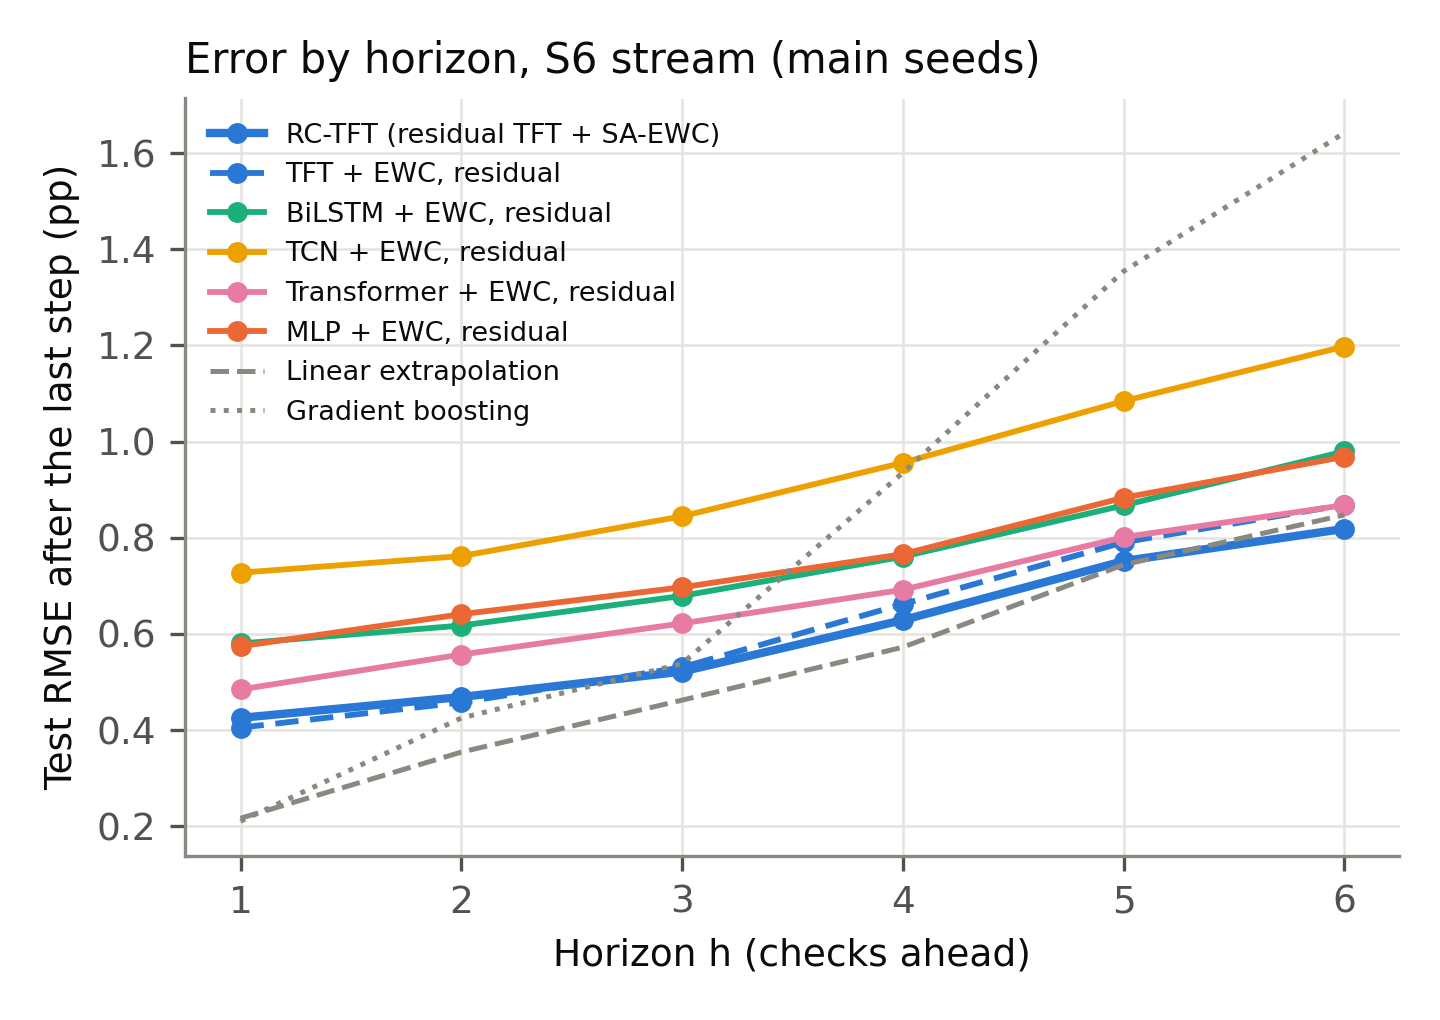

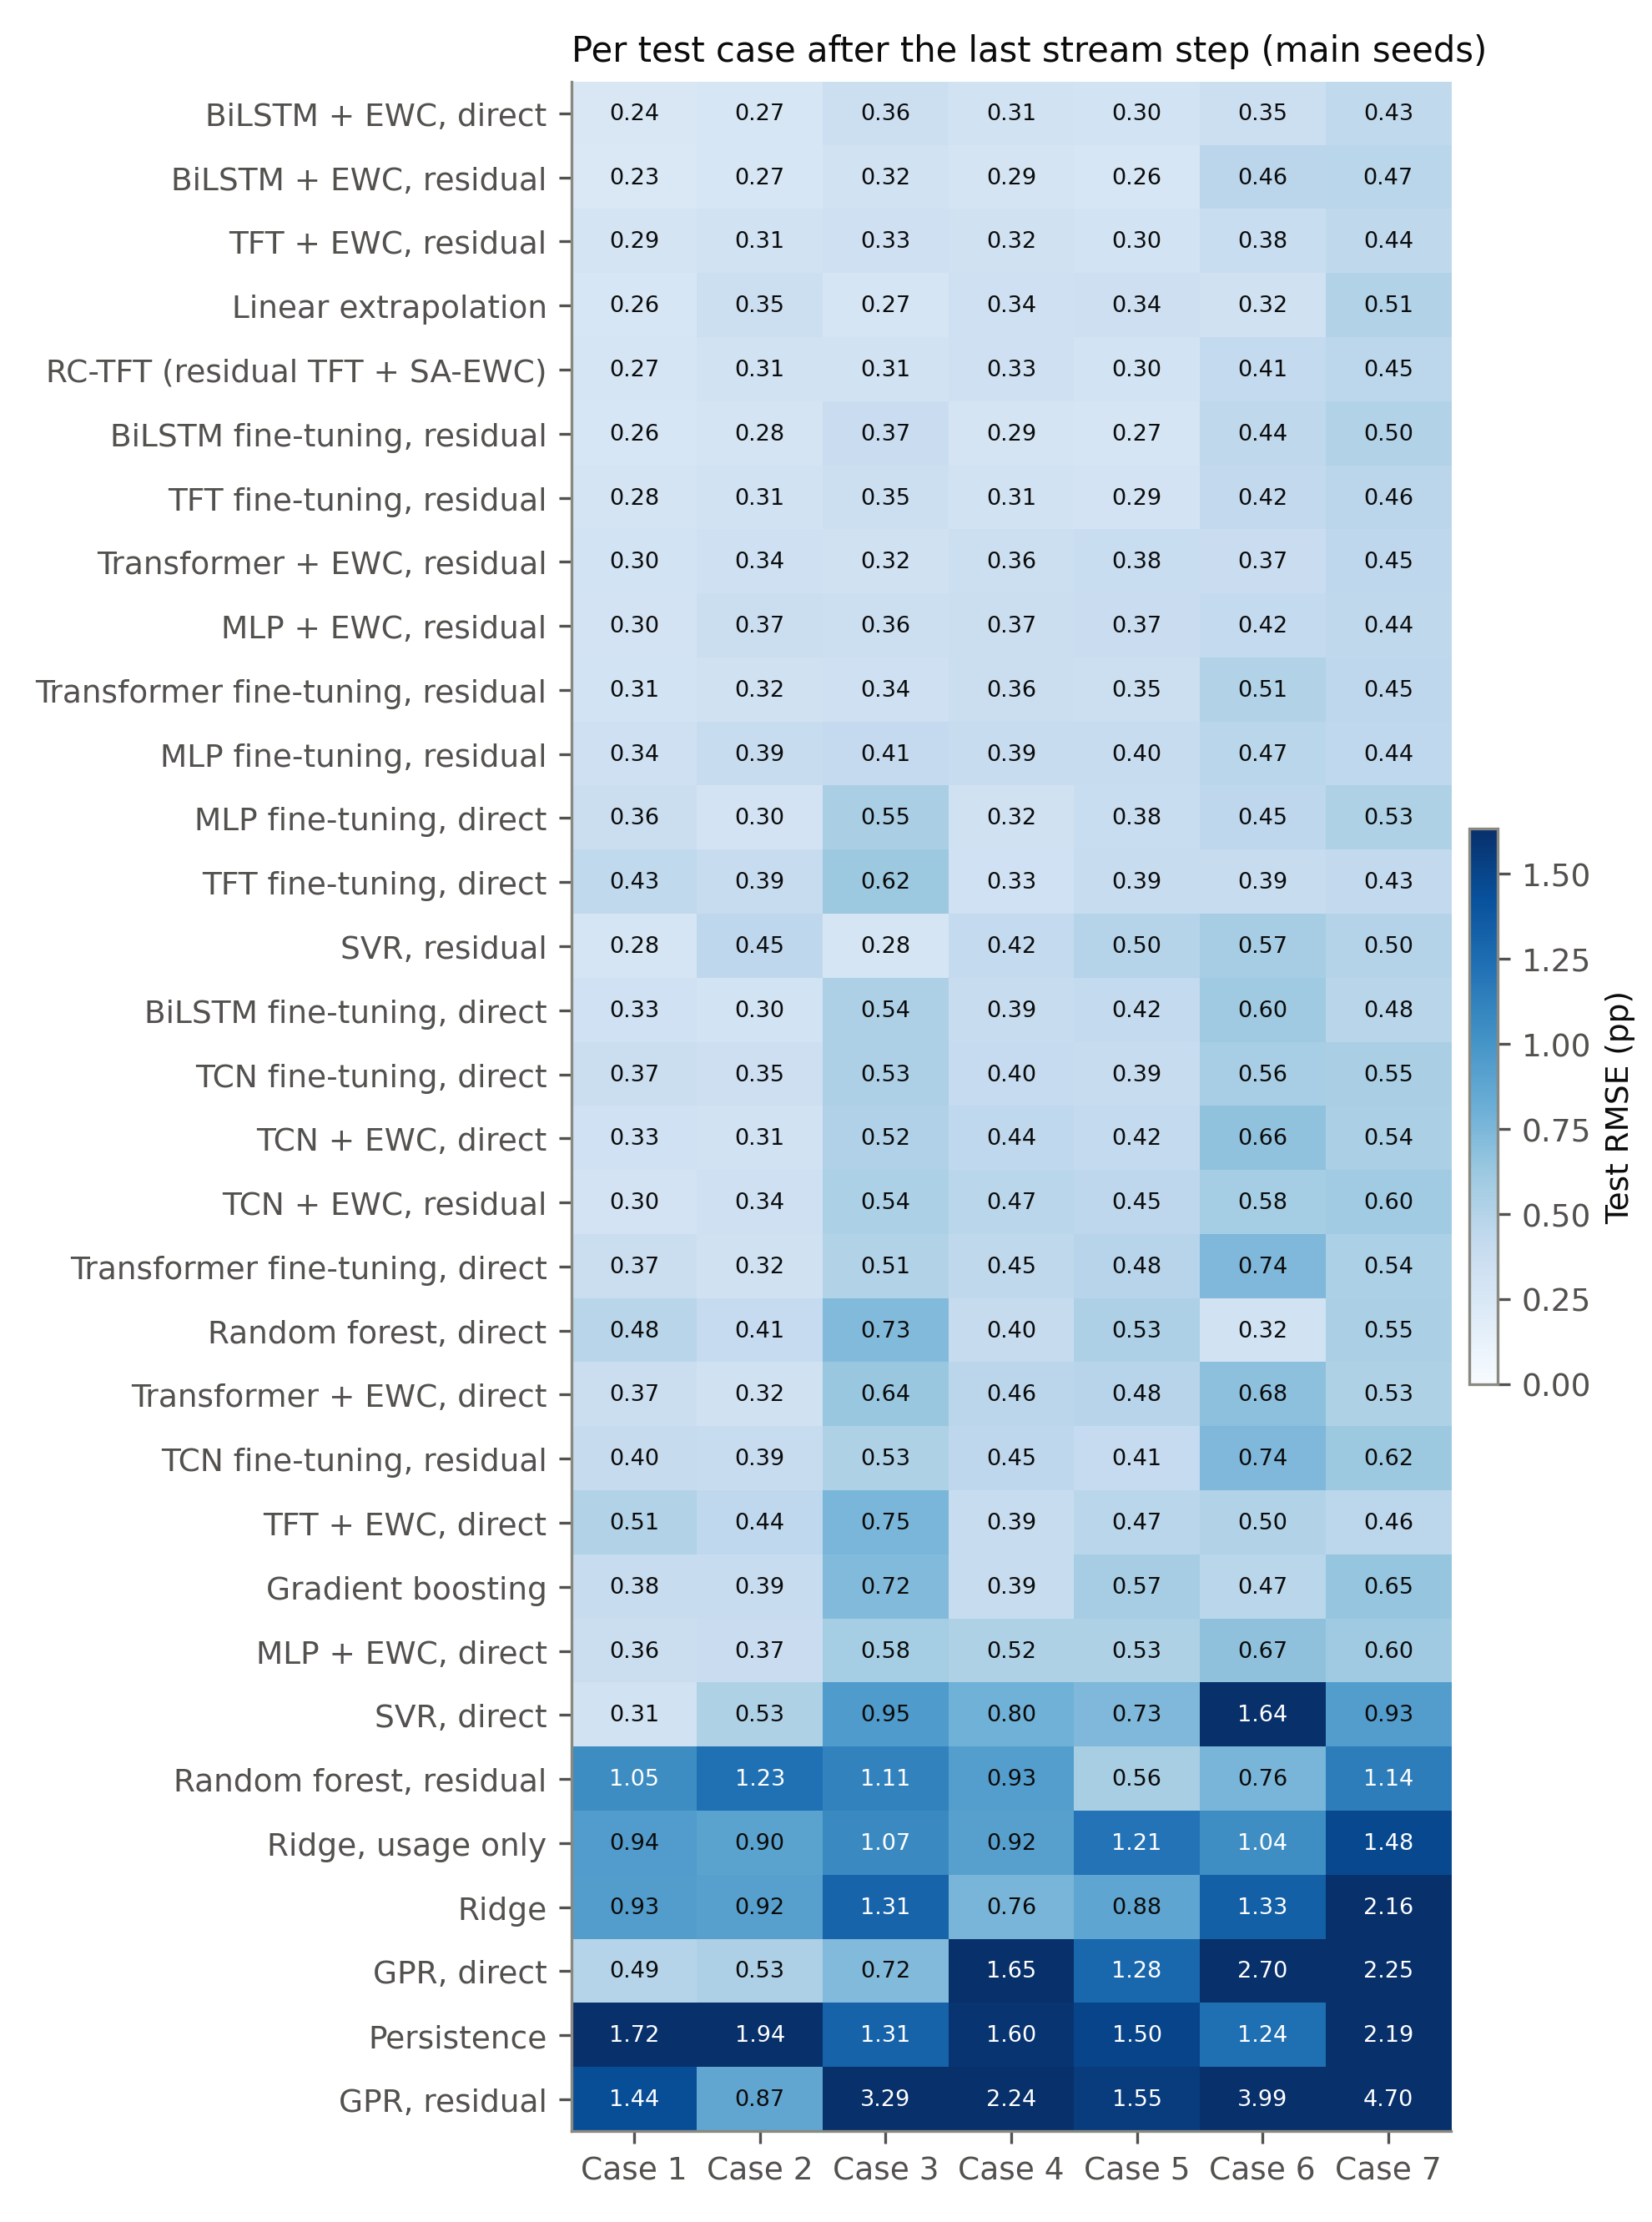

In [24]:
show("d24_horizon_e2.png", 560); show("d24_per_group_e1.png", 760)

## 6. RC-TFT and the literature baselines (D24)

**RC-TFT** (Residual Continual TFT) is the proposed extension: the residual TFT above trained with *shift-adaptive* EWC, which protects an earlier battery group more when a new group's inputs differ more from it. It is compared with literature models: BiLSTM, TCN and a Transformer encoder (continual, fine-tuning and EWC), and GPR, random forest and SVR (fitted once on all training rows). The protocol was fixed before any run (D24 in `docs/DECISIONS.md`). This cell shows whatever D24 results are committed.

In [25]:
base_files = sorted(Path("results").glob("forecasting_d24_baselines_e*.json"))
full_files = sorted(Path("results").glob("forecasting_d24_e[12].json"))
if full_files:
    run("scripts/summarise_d24.py")
elif base_files:
    for f in base_files:
        b = json.loads(f.read_text())
        print(f"{f.name}: commit {b['environment']['git_commit'][:7]}, git_dirty={b['environment']['git_dirty']}")
        display(pd.DataFrame(b["baselines"])[["method", "final_avg_error"]].assign(label=lambda t: t["method"].map(O.label))
                .sort_values("final_avg_error").round(3))
    print("RC-TFT and the BiLSTM/TCN/Transformer baselines: not committed yet.")
else:
    print("No D24 results are committed yet: RC-TFT and the literature baselines have not been run on S6.")

# D24 results summary (generated by scripts/summarise_d24.py)

## E1 (horizons 1–3) — `forecasting_d24_e1.json`

- Commit `947b33a`, clean tree: True; Python 3.12.10, numpy 1.26.4, pandas 2.2.3, scikit-learn 1.5.2, torch 2.13.0+cpu; profile paper.
- Parts run: lstm_direct, lstm_residual, tcn_direct, tcn_residual, tft_residual_saewc, transformer_direct, transformer_residual.
- Parts not run: none.
- D23 reproduction check passed (main seed 0 order 0: 0.464125 vs 0.464125; replicate seed 5 order 3: 0.375621 vs 0.375621).
- Tuning: tft_residual_saewc: lr 0.003, lambda 1.0; lstm_residual: lr 0.01, lambda 0.1; tcn_residual: lr 0.01, lambda 100000.0; transformer_residual: lr 0.003, lambda 1000.0; lstm_direct: lr 0.01, lambda 100000.0; tcn_direct: lr 0.003, lambda 1.0; transformer_direct: lr 0.003, lambda 100.0.
- Parameters: tft 12,708, lstm 11,181, tcn 12,205, transformer 11,905.

| Method | RMSE main (s.d.) | RMSE replicate (s.d.) | Forgetting (main) | BWT (main) |
|---|---|---|---|---|
| 

## 7. Shrinkage, unseen conditions and forecast intervals (D25–D27, committed results)

Three follow-up experiments, each specified and committed before it was run (`docs/DECISIONS.md`):

- **D25 (S6 stream):** the residual TFT + EWC's correction is shrunk towards linear extrapolation per horizon (factor α_h fitted on validation rows, 0 = extrapolation, 1 = full correction), and split-conformal 90 % / 80 % intervals are added.
- **D26 (unseen condition, P2):** the shrunk residual TFT + EWC is streamed over six S6 conditions and tested on the seventh, against gradient boosting, linear extrapolation and the same TFT trained jointly.
- **D27 (intervals on unseen conditions):** conformal intervals calibrated by leaving one training condition out, for gradient boosting and extrapolation. Deterministic, so a result must hold in both E1 and E2 instead of two seed sets.

D25 E1: commit a59debb, git_dirty=False
D25 E2: commit a59debb, git_dirty=False
E1 | baselines: {'linear_extrapolation': 0.343, 'persistence': 1.644}


final_avg_error_mean           cov90_mean  \
set                                            main replicate       main   
method                                                                     
linear_extrapolation_conformal                  NaN       NaN      0.924   
tft_pre_residual_ewc                          0.557     0.540        NaN   
tft_pre_residual_ewc_shrunk                   0.422     0.415      0.773   
tft_residual_ewc                              0.339     0.314        NaN   
tft_residual_ewc_shrunk                       0.318     0.308      0.714   

                                         is90_mean            
set                            replicate      main replicate  
method                                                        
linear_extrapolation_conformal     0.924     1.910     1.910  
tft_pre_residual_ewc                 NaN       NaN       NaN  
tft_pre_residual_ewc_shrunk        0.805     2.553     2.358  
tft_residual_ewc                     NaN       NaN       NaN  
tft_residual_ewc_shrunk            0.716     1.932     1.985

,a,b,metric,diff_main,diff_replicate,p_holm_main,p_holm_replicate,verdict
0,tft_residual_ewc_shrunk,linear_extrapolation,final_avg_error,-0.025,-0.035,0.003,0.001,practically equivalent
1,tft_pre_residual_ewc_shrunk,linear_extrapolation,final_avg_error,0.079,0.072,0.000,0.000,"replicated, a worse"
2,tft_pre_residual_ewc,tft_residual_ewc,final_avg_error,0.218,0.227,0.000,0.000,"replicated, a worse"
3,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is90,0.022,0.075,0.863,0.546,not replicated
4,tft_residual_ewc_shrunk,tft_residual_ewc,final_avg_error,-0.021,-0.006,0.000,0.000,practically equivalent
5,tft_residual_ewc_shrunk,tft_residual_ewc,forgetting,-0.016,-0.003,0.009,0.485,practically equivalent
6,tft_pre_residual_ewc_shrunk,tft_pre_residual_ewc,final_avg_error,-0.135,-0.125,0.000,0.000,"replicated, a better"
7,tft_pre_residual_ewc_shrunk,tft_pre_residual_ewc,forgetting,0.010,0.061,0.624,0.000,not replicated
8,tft_pre_residual_ewc,tft_residual_ewc,forgetting,-0.006,-0.033,1.000,0.022,practically equivalent
9,tft_pre_residual_ewc_shrunk,tft_residual_ewc_shrunk,final_avg_error,0.104,0.107,0.000,0.000,"replicated, a worse"


E2 | baselines: {'linear_extrapolation': 0.485, 'persistence': 2.667}


final_avg_error_mean           cov90_mean  \
set                                            main replicate       main   
method                                                                     
linear_extrapolation_conformal                  NaN       NaN      0.948   
tft_pre_residual_ewc                          0.541     0.593        NaN   
tft_pre_residual_ewc_shrunk                   0.500     0.525      0.810   
tft_residual_ewc                              0.561     0.534        NaN   
tft_residual_ewc_shrunk                       0.498     0.493      0.808   

                                         is90_mean            
set                            replicate      main replicate  
method                                                        
linear_extrapolation_conformal     0.948     3.048     3.048  
tft_pre_residual_ewc                 NaN       NaN       NaN  
tft_pre_residual_ewc_shrunk        0.815     3.029     3.095  
tft_residual_ewc                     NaN       NaN       NaN  
tft_residual_ewc_shrunk            0.799     3.057     3.021

,a,b,metric,diff_main,diff_replicate,p_holm_main,p_holm_replicate,verdict
0,tft_residual_ewc_shrunk,linear_extrapolation,final_avg_error,0.013,0.008,1.000,0.992,practically equivalent
1,tft_pre_residual_ewc_shrunk,linear_extrapolation,final_avg_error,0.015,0.040,1.000,0.033,practically equivalent
2,tft_pre_residual_ewc,tft_residual_ewc,final_avg_error,-0.020,0.059,1.000,0.062,not replicated
3,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is90,0.010,-0.027,0.791,0.389,practically equivalent
4,tft_residual_ewc_shrunk,tft_residual_ewc,final_avg_error,-0.063,-0.041,0.000,0.000,not replicated
5,tft_residual_ewc_shrunk,tft_residual_ewc,forgetting,-0.008,-0.002,1.000,1.000,practically equivalent
6,tft_pre_residual_ewc_shrunk,tft_pre_residual_ewc,final_avg_error,-0.042,-0.068,0.000,0.000,not replicated
7,tft_pre_residual_ewc_shrunk,tft_pre_residual_ewc,forgetting,-0.008,-0.013,1.000,1.000,practically equivalent
8,tft_pre_residual_ewc,tft_residual_ewc,forgetting,-0.016,0.007,1.000,1.000,practically equivalent
9,tft_pre_residual_ewc_shrunk,tft_residual_ewc_shrunk,final_avg_error,0.002,0.032,1.000,0.453,practically equivalent


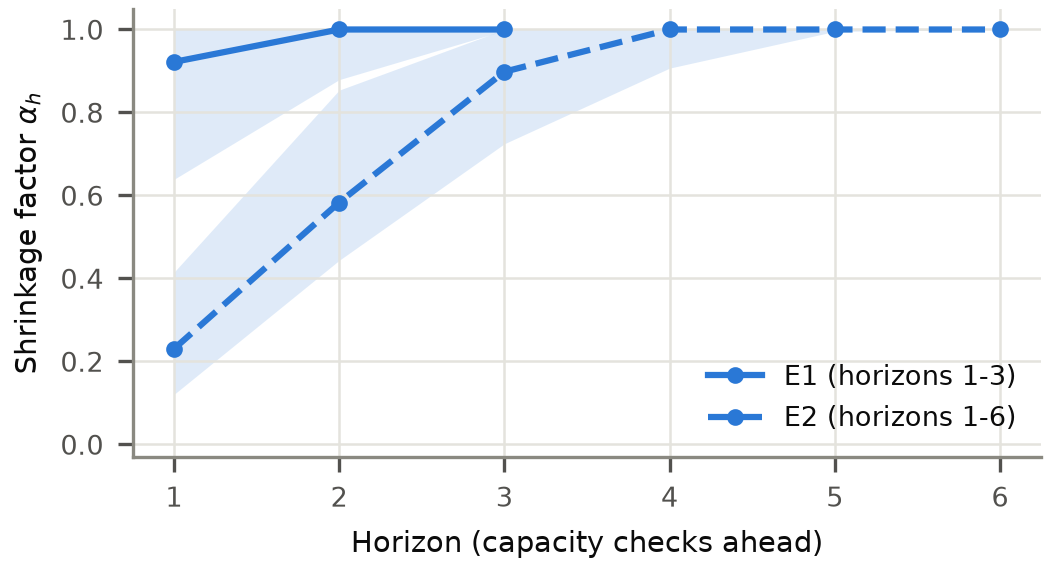

In [26]:
def results(d, exp):
    r = json.loads((REPO_ROOT / "results" / f"forecasting_{d}_{exp}.json").read_text())
    print(f"{d.upper()} {exp.upper()}: commit {r['environment']['git_commit'][:7]}, git_dirty={r['environment']['git_dirty']}")
    return r

def verdicts(r):
    v = pd.DataFrame(r["verdicts"])
    return v[["a", "b", "metric", "diff_main", "diff_replicate", "p_holm_main", "p_holm_replicate", "verdict"]].round(3)

d25 = {exp: results("d25", exp) for exp in ("e1", "e2")}
for exp in ("e1", "e2"):
    s = pd.DataFrame(d25[exp]["summary"])
    print(exp.upper(), "| baselines:", {b["method"]: round(b["final_avg_error"], 3) for b in d25[exp]["baselines"]})
    display(s.pivot(index="method", columns="set", values=["final_avg_error_mean", "cov90_mean", "is90_mean"]).round(3))
    display(verdicts(d25[exp]))
show("d25_shrinkage.png", 520)

**Reading D25.** Shrinkage makes the residual TFT + EWC practically equivalent to linear extrapolation at every horizon (it removes its replicated loss at h = 1–2), but does not beat it; the correction is turned down most at h = 1 in E2 (figure). Its 90 % intervals under-cover on the stream (0.71–0.81, against 0.92–0.95 for extrapolation). Pretraining on the first-life pool makes it worse for horizons 1–3.

D26 E1: commit 9866d7a, git_dirty=False
D26 E2: commit 9866d7a, git_dirty=False
E1 | deterministic baselines (all origins / H+): {'persistence': (2.817, 2.663), 'linear_extrapolation': (1.372, 0.86), 'ridge_shared': (0.771, 0.691), 'gbm_shared': (0.535, 0.508)}


p2_error_mean           p2_error_hplus_mean  \
set                                     main replicate                main   
method                                                                       
linear_extrapolation_conformal           NaN       NaN                 NaN   
tft_residual_ewc                       0.885     0.900               0.793   
tft_residual_ewc_shrunk                0.924     0.945               0.738   
tft_residual_joint                     0.568     0.577               0.538   

                                         cov90_mean            
set                            replicate       main replicate  
method                                                         
linear_extrapolation_conformal       NaN      0.743     0.743  
tft_residual_ewc                   0.802        NaN       NaN  
tft_residual_ewc_shrunk            0.743      0.661     0.655  
tft_residual_joint                 0.550        NaN       NaN

,a,b,metric,diff_main,diff_replicate,p_holm_main,p_holm_replicate,verdict
0,tft_residual_ewc_shrunk,linear_extrapolation,p2_error_hplus,-0.122,-0.116,0.0,0.0,"replicated, a better"
1,tft_residual_ewc_shrunk,linear_extrapolation,p2_error,-0.448,-0.427,0.0,0.0,"replicated, a better"
2,tft_residual_ewc_shrunk,gbm_shared,p2_error,0.389,0.410,0.0,0.0,"replicated, a worse"
3,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is90,-2.350,-2.196,0.0,0.0,"replicated, a better"
4,tft_residual_ewc_shrunk,linear_extrapolation,p2_error_hminus,-2.285,-2.159,0.0,0.0,"replicated, a better"
5,tft_residual_ewc_shrunk,gbm_shared,p2_error_hminus,1.536,1.661,0.0,0.0,"replicated, a worse"
6,tft_residual_ewc_shrunk,tft_residual_ewc,p2_error,0.040,0.045,0.0,0.0,practically equivalent
7,tft_residual_ewc,tft_residual_joint,p2_error,0.317,0.323,0.0,0.0,"replicated, a worse"
8,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is80,-1.485,-1.396,0.0,0.0,"replicated, a better"


E2 | deterministic baselines (all origins / H+): {'persistence': (4.898, 4.732), 'linear_extrapolation': (2.3, 1.62), 'ridge_shared': (1.299, 1.258), 'gbm_shared': (1.051, 1.049)}


p2_error_mean           p2_error_hplus_mean  \
set                                     main replicate                main   
method                                                                       
linear_extrapolation_conformal           NaN       NaN                 NaN   
tft_residual_ewc                       1.595     1.623               1.464   
tft_residual_ewc_shrunk                1.620     1.653               1.418   
tft_residual_joint                     1.214     1.184               1.216   

                                         cov90_mean            
set                            replicate       main replicate  
method                                                         
linear_extrapolation_conformal       NaN      0.763     0.763  
tft_residual_ewc                   1.485        NaN       NaN  
tft_residual_ewc_shrunk            1.441      0.682     0.671  
tft_residual_joint                 1.189        NaN       NaN

,a,b,metric,diff_main,diff_replicate,p_holm_main,p_holm_replicate,verdict
0,tft_residual_ewc_shrunk,linear_extrapolation,p2_error_hplus,-0.201,-0.179,0.0,0.0,"replicated, a better"
1,tft_residual_ewc_shrunk,linear_extrapolation,p2_error,-0.680,-0.647,0.0,0.0,"replicated, a better"
2,tft_residual_ewc_shrunk,gbm_shared,p2_error,0.570,0.603,0.0,0.0,"replicated, a worse"
3,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is90,-3.571,-3.183,0.0,0.0,"replicated, a better"
4,tft_residual_ewc_shrunk,linear_extrapolation,p2_error_hminus,-3.700,-3.615,0.0,0.0,"replicated, a better"
5,tft_residual_ewc_shrunk,gbm_shared,p2_error_hminus,2.361,2.446,0.0,0.0,"replicated, a worse"
6,tft_residual_ewc_shrunk,tft_residual_ewc,p2_error,0.025,0.030,0.0,0.0,practically equivalent
7,tft_residual_ewc,tft_residual_joint,p2_error,0.381,0.440,0.0,0.0,"replicated, a worse"
8,tft_residual_ewc_shrunk,linear_extrapolation_conformal,is80,-2.019,-1.858,0.0,0.0,"replicated, a better"


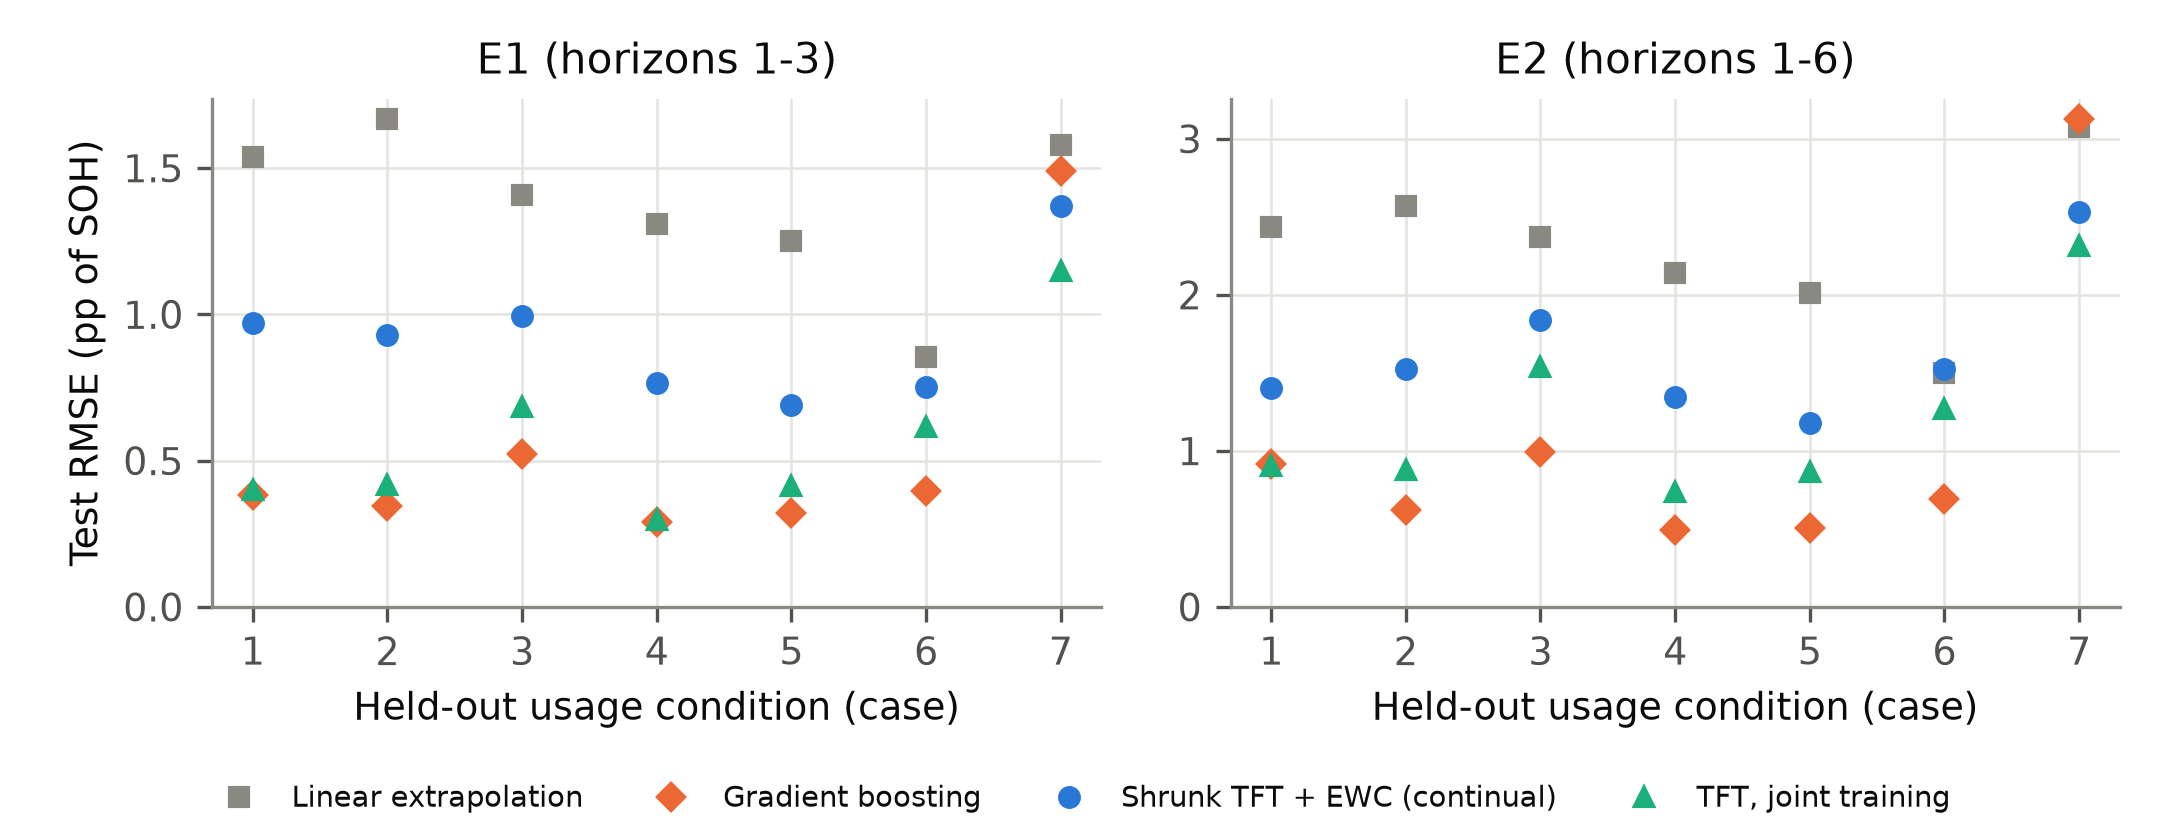

In [27]:
d26 = {exp: results("d26", exp) for exp in ("e1", "e2")}
for exp in ("e1", "e2"):
    s = pd.DataFrame(d26[exp]["summary"]).pivot(index="method", columns="set",
                                                values=["p2_error_mean", "p2_error_hplus_mean", "cov90_mean"])
    print(exp.upper(), "| deterministic baselines (all origins / H+):",
          {b["method"]: (round(b["p2_error"], 3), round(b["p2_error_hplus"], 3)) for b in d26[exp]["baselines"]})
    display(s.round(3))
    display(verdicts(d26[exp]))
show("d26_per_condition.png", 760)

**Reading D26.** On origins with a fade rate (H+), the shrunk residual TFT + EWC beats linear extrapolation (by 0.12 / 0.12 pp in E1 and 0.20 / 0.18 pp in E2, replicated), the first time it beats extrapolation. But gradient boosting is more accurate (by 0.39–0.60 pp, replicated, on six of the seven conditions), and the same TFT trained jointly beats its continual form by 0.32–0.44 pp (replicated). Its 90 % intervals, calibrated on the validation rows of the training conditions, cover only 0.66–0.68 on the unseen one.

D27 E1: commit 494b36f, git_dirty=False
D27 E2: commit 494b36f, git_dirty=False
E1 | reproduction of D26: {'gbm_rmse_abs_diff': {'case1': 0.0, 'case2': 0.0, 'case3': 0.0, 'case4': 0.0, 'case5': 0.0, 'case6': 0.0, 'case7': 0.0}, 'lin_val_abs_diff': {'is90': 0.0, 'cov90': 0.0, 'is80': 0.0, 'cov80': 0.0}, 'max_abs_diff': 0.0, 'passed': True} | overrides: {'allow_dirty': False, 'allow_unpinned': False}


,rule,coverage (pooled),min coverage over conditions,interval score (pp),width (pp),within one class,class correct when within one
0,"GBM, leave-one-condition-out",0.902,0.485,3.219,1.569,0.921,0.997
1,"Extrapolation, all origins",0.896,0.742,7.085,3.582,0.864,0.970
2,"Extrapolation, validation rows",0.743,0.395,8.475,1.508,0.940,0.955
3,"GBM, LOCO, per stratum",0.905,0.509,3.135,1.634,0.907,0.997
4,"Extrapolation, all origins, per stratum",0.900,0.715,4.839,3.187,0.859,0.989


Q2, GBM-LOCO minus extrapolation (all origins), interval score: mean -3.87 pp, GBM better on 6/7 conditions, exact Wilcoxon p = 0.047
E2 | reproduction of D26: {'gbm_rmse_abs_diff': {'case1': 0.0, 'case2': 0.0, 'case3': 0.0, 'case4': 0.0, 'case5': 0.0, 'case6': 0.0, 'case7': 0.0}, 'lin_val_abs_diff': {'is90': 0.0, 'cov90': 0.0, 'is80': 0.0, 'cov80': 0.0}, 'max_abs_diff': 0.0, 'passed': True} | overrides: {'allow_dirty': False, 'allow_unpinned': False}


,rule,coverage (pooled),min coverage over conditions,interval score (pp),width (pp),within one class,class correct when within one
0,"GBM, leave-one-condition-out",0.896,0.384,6.669,2.944,0.871,0.994
1,"Extrapolation, all origins",0.893,0.714,11.781,6.643,0.768,0.969
2,"Extrapolation, validation rows",0.763,0.436,13.531,3.067,0.881,0.948
3,"GBM, LOCO, per stratum",0.895,0.393,6.625,3.027,0.861,0.995
4,"Extrapolation, all origins, per stratum",0.899,0.670,8.451,5.212,0.795,0.992


Q2, GBM-LOCO minus extrapolation (all origins), interval score: mean -5.11 pp, GBM better on 6/7 conditions, exact Wilcoxon p = 0.297


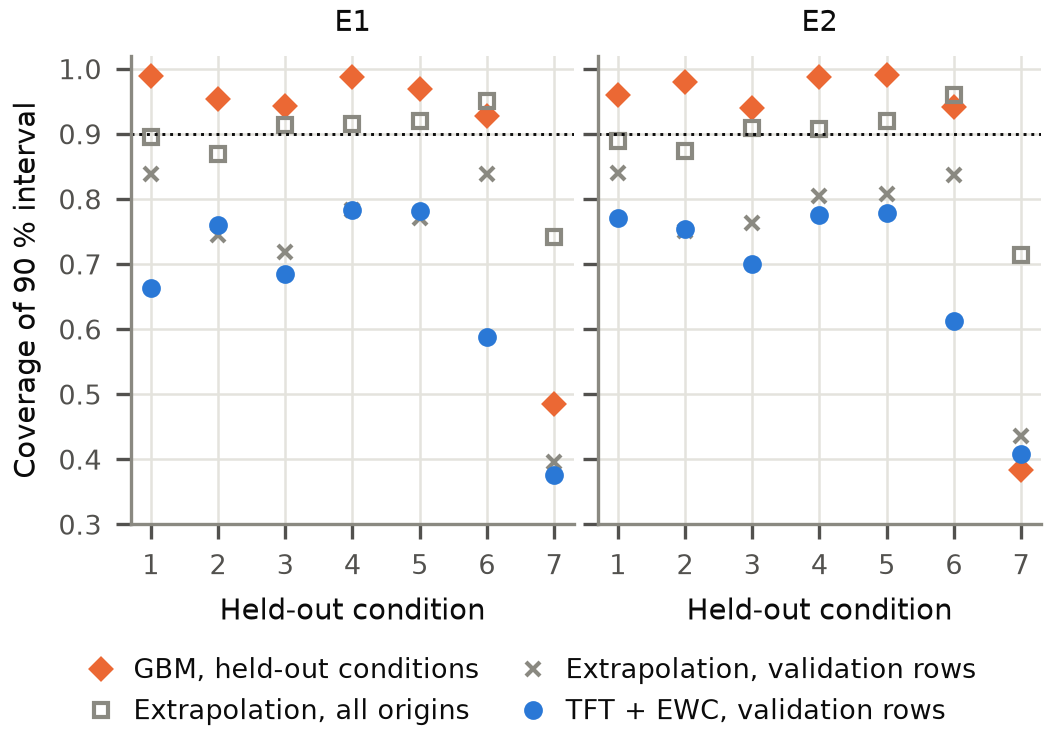

In [28]:
rule_names = {"gbm_loco": "GBM, leave-one-condition-out", "lin_all": "Extrapolation, all origins",
              "lin_val": "Extrapolation, validation rows", "gbm_loco_mondrian": "GBM, LOCO, per stratum",
              "lin_all_mondrian": "Extrapolation, all origins, per stratum"}
d27 = {exp: results("d27", exp) for exp in ("e1", "e2")}
for exp in ("e1", "e2"):
    r = d27[exp]
    print(exp.upper(), "| reproduction of D26:", r["reproduction_check"], "| overrides:", r["overrides"])
    rows = [{"rule": rule_names[k], "coverage (pooled)": v["90"]["coverage_pooled"],
             "min coverage over conditions": min(v["90"]["coverage_per_fold"].values()),
             "interval score (pp)": v["90"]["interval_score"], "width (pp)": v["90"]["width"],
             "within one class": v["90"]["decided_share"], "class correct when within one": v["90"]["decided_agreement"]}
            for k, v in r["summary"].items()]
    display(pd.DataFrame(rows).round(3))
    q2 = r["q2_test"]
    print(f"Q2, GBM-LOCO minus extrapolation (all origins), interval score: mean {q2['mean_diff']:.2f} pp, "
          f"GBM better on {q2['n_gbm_better']}/7 conditions, exact Wilcoxon p = {q2['p_value']:.3f}")
show("d27_coverage.png", 520)

**Reading D27.**
- **Coverage (registered question 1): positive.** Gradient-boosting intervals calibrated by leaving one condition out cover 0.90 at the nominal 90 % in both E1 and E2 (threshold 0.85).
- **Better than calibrated extrapolation (question 2): not established.** Lower interval score on six of seven conditions, significant in E1 (p = 0.047) but not in E2 (p = 0.30).
- **Cause of the D26 shortfall (question 3):** calibrating extrapolation, which has no fitted parameters, on all origins of the training conditions instead of their mid-life validation rows raises its coverage from 0.74–0.76 to 0.89–0.90, so the calibration rows caused most of it.
- **Exception:** case 7 (100 % depth of discharge, outside the range of the other conditions) is covered only 0.38–0.48; the pooled 0.90 hides this.
- **Reuse decisions:** 87–92 % of forecasts have a 90 % interval within one reuse class, and 99.4–99.7 % of those classes are correct; the rest are flagged as uncertain.

## 8. Conclusions

### Proposed model against existing models (section 5)

Every number below is printed by the cells above (diff = TFT + EWC − other, main / replicate, pp; verdicts by the D21 rule).

**Against the conventional models, residual TFT + EWC is better, and every such difference replicates, except against linear extrapolation:**
- Gradient boosting: −0.112 / −0.138 (E1) and −0.337 / −0.365 (E2).
- Ridge (schedule and shared inputs) and persistence: between −0.74 and −2.13 in both experiments.
- Linear extrapolation: practically equivalent in E1 (−0.004 / −0.029). Not replicated in E2 on the final error (+0.076 / +0.049), where linear extrapolation is lower; it is replicated better at horizons 1 and 2 (+0.189 / +0.144 and +0.103 / +0.076), and the two are practically equivalent at horizons 5 and 6.

**Against the other neural continual learners:**
- Residual TFT + EWC beats the direct TFT and direct MLP variants on final error, with every difference replicated except against direct fine-tuning (MLP in E1, TFT in both).
- Against the residual MLP it is replicated better than MLP fine-tuning in E1 only. Against MLP + EWC the E1 gap is below 0.05 pp in the main set, and in E2 the main set is not significant.

**What EWC adds** (residual TFT + EWC vs residual TFT fine-tuning):
- E1: practically equivalent on every metric.
- E2: forgetting is lower, and this replicates (0.093 vs 0.282 pp in the main set, 0.086 vs 0.220 in the replicate); backward transfer also replicates. The lower final error in E2 is not replicated.

**Claim for the paper (D23 alone):** a TFT that learns a correction to linear extrapolation, with EWC, is the best of the learned models on the S6 stream and clearly outperforms gradient boosting, ridge and persistence there, but it does not beat simple linear extrapolation. EWC's replicated benefit is reduced forgetting over the longer horizons (E2). These are results on S6 only, with SOH relative to the first RPT capacity, so they are not comparable with literature numbers obtained on other datasets or SOH definitions.

### Follow-up experiments (sections 6 and 7) and the final claim
- **D24:** shift-adaptive EWC (RC-TFT) is practically equivalent to fixed-λ EWC; BiLSTM and Transformer with EWC match the residual TFT at horizons 1–3.
- **D25:** a shrunk correction makes the TFT practically equivalent to extrapolation on the stream at every horizon; it still does not beat it.
- **D26:** on an unseen usage condition the shrunk residual TFT + EWC beats extrapolation (replicated), but gradient boosting fitted on all conditions is 0.39–0.60 pp more accurate and the same TFT trained jointly beats its continual form by 0.32–0.44 pp (both replicated).
- **D27:** intervals for unseen conditions reach nominal coverage (0.90) only when calibrated on conditions held out from fitting, and not for a condition outside the training range.

**Final claim (paper, 8 pages):** at this data scale, the TFT + EWC hypothesis is not supported. Learning continually costs more than it gives, because storing every earlier group is cheap. For an unseen condition, the recommended practice is to fit on all conditions, calibrate intervals on held-out conditions and report coverage per condition.

### Big data, benchmarks and limitations
- **Preprocessing:** 901,974,259 raw rows reduced by Spark to 827 block rows of 21 inputs; Spark equals pandas on every block, and no block ends after a valid capacity check (section 3.1). The live run in section 3.2 repeats the pipeline on a real subset.
- **Benchmarks:** forgetting is negligible across the near-identical S1 cells and substantial across the S6 usage conditions; on unseen S6 conditions the learned models beat linear extrapolation and classify reuse classes C0–C3 far better than persistence (section 4.2); first-life pretraining does not improve S6 forecasts (section 4.3).
- **Limitations:** small numbers of groups (6 S1 cells; 2–3 S6 cells per condition); SOH relative to the first measured capacity, so results are not comparable with literature numbers on other datasets or SOH definitions; Spark ran on one machine in local mode, not on a cluster; S6 "second life" is continued ageing at 50 °C under the same protocol.

### Data sources and licences
- S6: W. Wheeler, Y. Bultel, P. Venet and A. Sari, "An ageing study of twenty 18650 lithium-ion Graphite/LFP cells in first and second life use," *Scientific Data* 12, 392 (2025); dataset doi:10.57745/OLBXKT, CC BY 4.0.
- S1: K. Moy *et al.*, *Data in Brief* 57, 111046 (2024); dataset doi:10.17605/OSF.IO/8JNR5 (version 2), CC BY 4.0.
- S7–S9 (pretraining pool): see `docs/EXTERNAL_DATA.md`, which records the citation, licence and hashes of every source.